# Deprem Yer Hareketi Tahmini — Geliştirilmiş ve Sızıntısız Modelleme

Bu notebook, `deprem_model-2.ipynb` çalışmasının bilimsel olarak yeniden düzenlenmiş halidir.
Mevcut notebook **baseline** olarak değiştirilmeden bırakılmıştır; burada aynı yaklaşım
(`Mevcut yaklaşım`) yeniden kurulup geliştirilmiş modelle **aynı bağımsız test setinde** karşılaştırılır.

**Hedefler:** `PGA-RotD50_(g)`, `PGV-RotD50_(cm/s)`, `PGD-RotD50_(cm)` (çok çıktılı regresyon)

**Mevcut notebook'ta tespit edilen başlıca sorunlar**

| # | Sorun | Etkisi |
|---|---|---|
| 1 | Hedefler `log1p` ile dönüştürülmüş; değerler çok küçük (medyan PGA ≈ 0.0006 g) olduğundan `log1p(y) ≈ y` | Model fiilen ham ölçekte eğitiliyor, küçük genlikli kayıtlar (verinin çoğu) kötü tahmin ediliyor |
| 2 | Rastgele train/test ayrımı; aynı depremin kayıtları iki sete dağılıyor | Test skoru, yeni bir deprem için gerçek performansa göre iyimser |
| 3 | `Depth` / `Rhyp` sütunlarında `-999` eksik-değer kodu | Notebook'ta tesadüfen (log1p → NaN) atılıyor; açık bir kural yok |
| 4 | `Vs30 = -1` (bilinmiyor) olan tüm kayıtlar siliniyor (~%27) | Gereksiz veri kaybı |
| 5 | Tek train/test ayrımında modeller test skoruna göre sıralanıp seçiliyor | Seçim yanlılığı (test seti model seçiminde kullanılıyor) |
| 6 | Birimleri farklı 3 hedefin RMSE/MAE'si tek sayıda ortalanıyor; R² (orijinal) birkaç büyük kayda duyarlı | Metrikler yanıltıcı |

**Bu notebook'taki yaklaşım:** olay (deprem) bazlı ayrım → yalnızca eğitim setinde 5-katlı `GroupKFold`
çapraz doğrulama → hedef dönüşümü, özellik seti ve hiperparametreler yalnızca CV ile seçilir →
test seti **en sonda bir kez** kullanılır. Tüm ön işleme adımları (`imputation`, `scaling`,
özellik üretimi) `Pipeline` içindedir ve her katmanda yalnızca eğitim verisine fit edilir.

> Colab'da çalıştırırken: `deprem.csv` (veya `deprem_veri.csv`) çalışma klasöründe ya da Google
> Drive'da olmalı. Eksik paketler (optuna, catboost, shap…) ilk hücrede otomatik kurulur.

## 1. Imports

In [ ]:
import os
import sys
import re
import json
import glob
import time
import warnings
import subprocess
import importlib.util

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
os.environ.setdefault("PYTHONHASHSEED", "42")

# Colab'da eksik paketleri kur (yerelde kurulum yapılmaz, yalnızca uyarı verilir)
IN_COLAB = "google.colab" in sys.modules
_paketler = {"optuna": "optuna", "xgboost": "xgboost", "lightgbm": "lightgbm",
             "catboost": "catboost", "shap": "shap"}
_eksik = [p for m, p in _paketler.items() if importlib.util.find_spec(m) is None]
if _eksik and IN_COLAB:
    print("Kuruluyor:", _eksik)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_eksik])
elif _eksik:
    print("Eksik paketler (ilgili modeller atlanacak):", _eksik)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy import stats

import sklearn
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.multioutput import MultiOutputRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor,
                              GradientBoostingRegressor, HistGradientBoostingRegressor)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (r2_score, mean_squared_error, mean_absolute_error,
                             median_absolute_error, explained_variance_score,
                             mean_absolute_percentage_error)

import optuna

HAS_XGB = importlib.util.find_spec("xgboost") is not None
HAS_LGBM = importlib.util.find_spec("lightgbm") is not None
HAS_CAT = importlib.util.find_spec("catboost") is not None
HAS_SHAP = importlib.util.find_spec("shap") is not None
if HAS_XGB:
    from xgboost import XGBRegressor
if HAS_LGBM:
    from lightgbm import LGBMRegressor
if HAS_CAT:
    from catboost import CatBoostRegressor
if HAS_SHAP:
    import shap

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | optuna {optuna.__version__}")
print(f"XGBoost={HAS_XGB}  LightGBM={HAS_LGBM}  CatBoost={HAS_CAT}  SHAP={HAS_SHAP}")

Kuruluyor: ['optuna', 'catboost']
Python 3.13.16 | numpy 2.1.3 | pandas 2.2.3 | scikit-learn 1.6.1 | optuna 5.0.0
XGBoost=True  LightGBM=True  CatBoost=True  SHAP=True


## 2. Configuration

In [ ]:
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

HEDEFLER = ["PGA-RotD50_(g)", "PGV-RotD50_(cm/s)", "PGD-RotD50_(cm)"]
HEDEF_KISA = ["PGA", "PGV", "PGD"]
HEDEF_BIRIM = {"PGA": "g", "PGV": "cm/s", "PGD": "cm"}

# Bilimsel filtreler (modellemeden ÖNCE uygulanır)
FILTRE_MW_MIN = 3.0
FILTRE_RHYP_MAX = 300.0
FILTRE_DEPTH_MAX = 30.0

TEST_ORANI = 0.15      # olay bazlı bağımsız test seti
N_FOLDS = 5            # eğitim seti içinde GroupKFold
EPS = 1e-8             # ln için alt sınır (yalnızca negatif/0 tahmin üreten modellerde devreye girer)

# Hızlı deneme modu (yalnızca kodu test etmek için): DEPREM_HIZLI=1
HIZLI = os.environ.get("DEPREM_HIZLI") == "1"
N_TRIALS = {"XGBoost": 25, "LightGBM": 30, "CatBoost": 12, "HistGradientBoosting": 20,
            "Gradient Boosting": 10, "Random Forest": 15, "Extra Trees": 15}
N_BOOTSTRAP = 1000
N_PERM_REPEATS = 10
SHAP_ORNEK = 1000
if HIZLI:
    N_TRIALS = {k: 2 for k in N_TRIALS}
    N_BOOTSTRAP, N_PERM_REPEATS, SHAP_ORNEK = 100, 2, 200

VERI_ADAYLARI = ["deprem.csv", "deprem_veri.csv", "../deprem_veri.csv",
                 "/content/deprem.csv", "/content/deprem_veri.csv"]
CIKTI_KLASORU = "ciktilar"
os.makedirs(CIKTI_KLASORU, exist_ok=True)

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
optuna.logging.set_verbosity(optuna.logging.WARNING)

## 3. Data Loading

Dosyadaki `T0.010s_(g) … T20.000s_(g)` spektral ivme sütunları **okunmaz**: bunlar aynı kaydın
tepki spektrumudur ve hedefle neredeyse özdeştir (ör. `T0.010s` ≈ PGA). Özellik olarak kullanılmaları
doğrudan **hedef sızıntısı** olur. Orijinal veri (`df_ham`) hiçbir adımda değiştirilmez.

In [ ]:
def veri_dosyasi_bul():
    for yol in VERI_ADAYLARI:
        if os.path.exists(yol):
            return yol
    if IN_COLAB:
        from google.colab import drive
        if not os.path.isdir("/content/drive/MyDrive"):
            drive.mount("/content/drive")
        for ad in ("deprem.csv", "deprem_veri.csv"):
            bulunan = sorted(glob.glob(f"/content/drive/MyDrive/**/{ad}", recursive=True))
            if bulunan:
                return bulunan[0]
    raise FileNotFoundError("deprem.csv / deprem_veri.csv bulunamadı; VERI_ADAYLARI listesine yolu ekleyin.")


SPEKTRAL_DESEN = re.compile(r"^T\d+(\.\d+)?s_\(g\)$")

VERI_YOLU = veri_dosyasi_bul()
tum_sutunlar = pd.read_csv(VERI_YOLU, nrows=0).columns.tolist()
spektral_sutunlar = [c for c in tum_sutunlar if SPEKTRAL_DESEN.match(c)]
df_ham = pd.read_csv(VERI_YOLU, usecols=[c for c in tum_sutunlar if c not in spektral_sutunlar])
KOORDINAT_VAR = {"EQ_Lat", "EQ_Lon"} <= set(df_ham.columns)

print(f"Dosya: {VERI_YOLU}")
print(f"Toplam sütun: {len(tum_sutunlar)}  |  dışarıda bırakılan spektral sütun: {len(spektral_sutunlar)}")
print(f"Okunan veri: {df_ham.shape}  |  sütunlar: {df_ham.columns.tolist()}")
print(f"Deprem koordinatları (EQ_Lat/EQ_Lon) mevcut: {KOORDINAT_VAR}")

if "T0.010s_(g)" in spektral_sutunlar:
    _s = pd.read_csv(VERI_YOLU, usecols=["T0.010s_(g)", HEDEFLER[0]])
    _r = np.corrcoef(np.log(_s.iloc[:, 0]), np.log(_s.iloc[:, 1]))[0, 1]
    print(f"Sızıntı kontrolü: corr(ln T0.010s, ln PGA) = {_r:.5f}  -> spektral sütunlar özellik olarak KULLANILMAZ")

Dosya: deprem_veri.csv
Toplam sütun: 121  |  dışarıda bırakılan spektral sütun: 111
Okunan veri: (45175, 10)  |  sütunlar: ['WF_ID', 'EQ_Lat', 'EQ_Lon', 'Depth', 'Mw', 'Rhyp', 'Vs30', 'PGA-RotD50_(g)', 'PGV-RotD50_(cm/s)', 'PGD-RotD50_(cm)']
Deprem koordinatları (EQ_Lat/EQ_Lon) mevcut: True
Sızıntı kontrolü: corr(ln T0.010s, ln PGA) = 0.99989  -> spektral sütunlar özellik olarak KULLANILMAZ


## 4. Data Quality Check

Eksik değerler, tekrar eden kayıtlar, eksik-değer kodları (`-999`, `-1`) ve fiziksel tutarlılık kontrol edilir.
Buradaki düzeltmeler **satır bazlı ve veriden parametre öğrenmeyen** kurallardır; bu nedenle ayrımdan
önce uygulanmaları sızıntı oluşturmaz.

In [ ]:
temel = ["Mw", "Rhyp", "Depth", "Vs30"] + (["EQ_Lat", "EQ_Lon"] if KOORDINAT_VAR else [])
print("Veri tipleri:", df_ham.dtypes.astype(str).to_dict())
print("\nEksik (NaN) değer sayısı:", df_ham.isna().sum()[lambda s: s > 0].to_dict() or "yok")
print("Tam tekrar eden satır:", int(df_ham.duplicated().sum()))
print("Tekrar eden WF_ID:", int(df_ham["WF_ID"].duplicated().sum()) if "WF_ID" in df_ham else "WF_ID yok")
print("Aynı özellik + aynı hedef:", int(df_ham.duplicated(subset=temel + HEDEFLER).sum()))
print("Aynı özellik, farklı hedef (farklı istasyon/bileşen):", int(df_ham.duplicated(subset=temel).sum()))

kodlar = pd.DataFrame({
    "Depth = -999": [(df_ham["Depth"] == -999).sum()],
    "Rhyp = -999": [(df_ham["Rhyp"] == -999).sum()],
    "Depth < 0": [(df_ham["Depth"] < 0).sum()],
    "Rhyp < 0": [(df_ham["Rhyp"] < 0).sum()],
    "Vs30 = -1": [(df_ham["Vs30"] == -1).sum()],
    "Vs30 < 0": [(df_ham["Vs30"] < 0).sum()],
    "Rhyp < Depth (geçerli satırlar)": [((df_ham["Rhyp"] < df_ham["Depth"]) & (df_ham["Depth"] >= 0)).sum()],
    **{f"{k} <= 0": [(df_ham[h] <= 0).sum()] for k, h in zip(HEDEF_KISA, HEDEFLER)},
}, index=["kayıt"]).T
kodlar

Veri tipleri: {'WF_ID': 'int64', 'EQ_Lat': 'float64', 'EQ_Lon': 'float64', 'Depth': 'float64', 'Mw': 'float64', 'Rhyp': 'float64', 'Vs30': 'int64', 'PGA-RotD50_(g)': 'float64', 'PGV-RotD50_(cm/s)': 'float64', 'PGD-RotD50_(cm)': 'float64'}

Eksik (NaN) değer sayısı: yok
Tam tekrar eden satır: 0
Tekrar eden WF_ID: 0
Aynı özellik + aynı hedef: 0
Aynı özellik, farklı hedef (farklı istasyon/bileşen): 1089


,kayıt
Depth = -999,26
Rhyp = -999,26
Depth < 0,26
Rhyp < 0,26
Vs30 = -1,12363
Vs30 < 0,12363
Rhyp < Depth (geçerli satırlar),0
PGA <= 0,0
PGV <= 0,0
PGD <= 0,0


In [ ]:
df = df_ham.copy()
n_baslangic = len(df)

# (1) -999 = eksik mesafe/derinlik. Rhyp modelin temel girdisidir, anlamlı biçimde doldurulamaz -> satır çıkarılır.
gecersiz = (df["Rhyp"] < 0) | (df["Depth"] < 0)
df = df[~gecersiz].copy()

# (2) Vs30 = -1 bilinmiyor demektir -> NaN yapılır; satır SİLİNMEZ.
#     Doldurma (imputation) Pipeline içinde, yalnızca eğitim katmanının medyanıyla yapılır.
df.loc[df["Vs30"] < 0, "Vs30"] = np.nan

# (3) Fiziksel tutarlılık kontrolleri
assert (df["Rhyp"] >= df["Depth"]).all(), "Rhyp < Depth olan satır var"
assert (df[HEDEFLER] > 0).all().all(), "Pozitif olmayan hedef var (ln dönüşümü tanımsız olur)"

print(f"Başlangıç: {n_baslangic}  |  -999 kodlu (Depth/Rhyp) çıkarılan: {int(gecersiz.sum())}  |  kalan: {len(df)}")
print(f"Vs30 bilinmeyen (NaN'a çevrilen): {int(df['Vs30'].isna().sum())} ({df['Vs30'].isna().mean():.1%})")

Başlangıç: 45175  |  -999 kodlu (Depth/Rhyp) çıkarılan: 26  |  kalan: 45149
Vs30 bilinmeyen (NaN'a çevrilen): 12363 (27.4%)


## 5. Earthquake Data Filtering

Belirlenen bilimsel filtreler modellemeden **önce** uygulanır:
`Mw >= 3`, `Rhyp <= 300 km`, `Depth <= 30 km` (veride sütun adı `Depth`).

In [ ]:
m_mw = df["Mw"] >= FILTRE_MW_MIN
m_r = df["Rhyp"] <= FILTRE_RHYP_MAX
m_d = df["Depth"] <= FILTRE_DEPTH_MAX
filtre_tablosu = pd.DataFrame({
    "Kural": ["Veri kalitesi sonrası", f"Mw < {FILTRE_MW_MIN}", f"Rhyp > {FILTRE_RHYP_MAX}",
              f"Depth > {FILTRE_DEPTH_MAX}", "Filtre sonrası kalan"],
    "Kayıt": [len(df), int((~m_mw).sum()), int((~m_r).sum()), int((~m_d).sum()), int((m_mw & m_r & m_d).sum())],
})

df = df[
    (df["Mw"] >= FILTRE_MW_MIN) &
    (df["Rhyp"] <= FILTRE_RHYP_MAX) &
    (df["Depth"] <= FILTRE_DEPTH_MAX)
].copy().reset_index(drop=True)
n_filtre = len(df)

# Olay (deprem) kimliği: koordinat varsa (EQ_Lat, EQ_Lon, Mw, Depth); yoksa (Mw, Depth).
# Koordinatsız durumda aynı Mw ve derinliğe sahip farklı depremler tek grupta birleşir;
# bu, ayrımı daha TUTUCU yapar (sızıntıyı artırmaz).
OLAY_ANAHTARI = ["EQ_Lat", "EQ_Lon", "Mw", "Depth"] if KOORDINAT_VAR else ["Mw", "Depth"]
df["OLAY_ID"] = df.groupby(OLAY_ANAHTARI, sort=True).ngroup()

print(filtre_tablosu.to_string(index=False))
print(f"\nOlay anahtarı: {OLAY_ANAHTARI}  ->  {df['OLAY_ID'].nunique()} olay/grup")
print(f"Vs30 bilinmeyen: {df['Vs30'].isna().mean():.1%}")

                Kural  Kayıt
Veri kalitesi sonrası  45149
             Mw < 3.0     46
         Rhyp > 300.0    864
         Depth > 30.0   1163
 Filtre sonrası kalan  43131

Olay anahtarı: ['EQ_Lat', 'EQ_Lon', 'Mw', 'Depth']  ->  5684 olay/grup
Vs30 bilinmeyen: 27.9%


## 6. Exploratory Data Analysis

### 6.1 Tanımlayıcı istatistikler

EDA yalnızca betimleme amaçlıdır: buradan hiçbir parametre öğrenilmez. Hedef dönüşümü ve özellik seçimi
kararları **Bölüm 10'da yalnızca eğitim seti üzerindeki CV** ile verilir.

In [ ]:
def ozet_istatistik(d, sutunlar):
    t = d[sutunlar].describe().T[["count", "mean", "std", "min", "max"]]
    t.insert(3, "median", d[sutunlar].median())
    t["skew"] = d[sutunlar].skew()
    t["kurtosis"] = d[sutunlar].kurt()
    return t

ist = ozet_istatistik(df, temel + HEDEFLER)
print(f"Kayıt sayısı: {len(df)}  |  girdi değişkeni: {len(temel)}  |  hedef: {len(HEDEFLER)}")
ist.style.format("{:.4g}")

Kayıt sayısı: 43131  |  girdi değişkeni: 6  |  hedef: 3


,count,mean,std,median,min,max,skew,kurtosis
Mw,4.313e+04,4.203,0.8035,4.1,3,7.8,1.185,2.418
Rhyp,4.313e+04,90.22,54.82,78,3,300,1.104,1.106
Depth,4.313e+04,10.3,4.545,10,0,30,0.9338,1.62
Vs30,3.108e+04,489,241.3,416,131,1822,1.28,1.827
EQ_Lat,4.313e+04,38.49,1.232,38.4,34.56,43.2,0.1281,-0.2649
EQ_Lon,4.313e+04,32.22,5.292,29.38,23.45,45.26,0.439,-1.311
PGA-RotD50_(g),4.313e+04,0.003239,0.02304,0.0005848,9.85e-06,1.383,26.94,989.4
PGV-RotD50_(cm/s),4.313e+04,0.2999,3.182,0.02545,0.00041,176.1,29.88,1113
PGD-RotD50_(cm),4.313e+04,0.2087,2.798,0.0026,2.4e-05,138.3,25.98,858.1


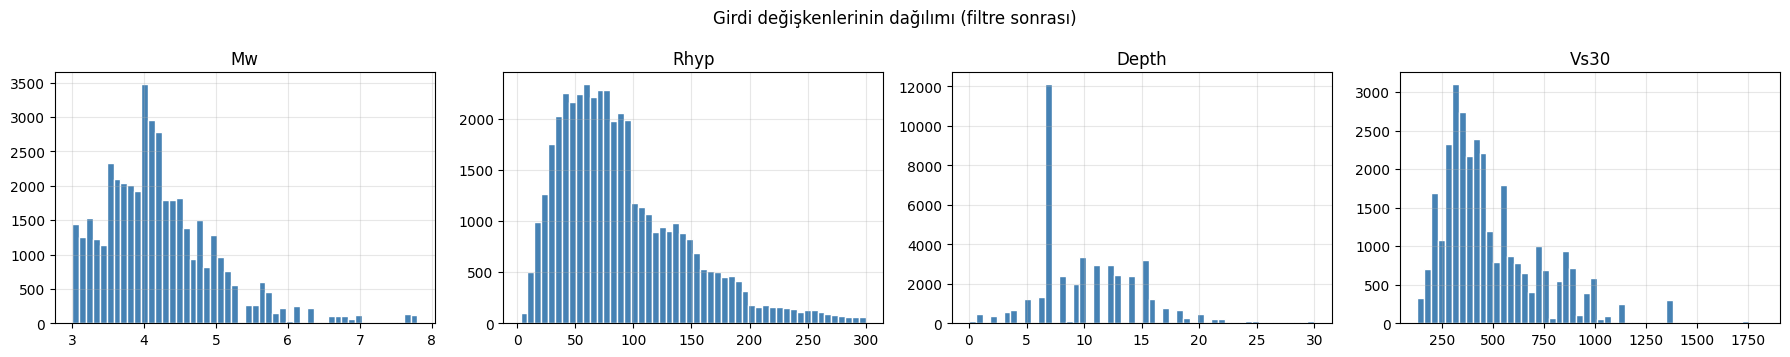

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
for ax, c in zip(axes, ["Mw", "Rhyp", "Depth", "Vs30"]):
    ax.hist(df[c].dropna(), bins=50, color="steelblue", edgecolor="white")
    ax.set_title(c)
fig.suptitle("Girdi değişkenlerinin dağılımı (filtre sonrası)")
plt.tight_layout(); plt.show()

### 6.2 Hedef değişkenin dağılımı ve dönüşüm analizi

Yer hareketi genlikleri fiziksel olarak **çarpımsal** (log-normal) davranır: hatalar mutlak değil,
oransal büyür. `log1p(y) = ln(1+y)` dönüşümü yalnızca `y` 1'e göre büyükse logaritmik davranır;
burada değerlerin çoğu 1'den çok küçük olduğundan `log1p(y) ≈ y` olur ve dönüşüm etkisizleşir.

In [ ]:
Y_df = df[HEDEFLER]
donusum_ist = pd.DataFrame({
    "medyan": Y_df.median().values,
    "log1p(y)/y (medyan oran)": (np.log1p(Y_df) / Y_df).median().values,
    "skew ham": Y_df.skew().values,
    "skew log1p": np.log1p(Y_df).skew().values,
    "skew ln": np.log(Y_df).skew().values,
    "kurtosis ham": Y_df.kurt().values,
    "kurtosis ln": np.log(Y_df).kurt().values,
}, index=HEDEF_KISA)
print("log1p(y)/y ≈ 1 ise log1p dönüşümü fiilen hiçbir şey yapmıyor demektir.")
donusum_ist.style.format("{:.4g}")

log1p(y)/y ≈ 1 ise log1p dönüşümü fiilen hiçbir şey yapmıyor demektir.


,medyan,log1p(y)/y (medyan oran),skew ham,skew log1p,skew ln,kurtosis ham,kurtosis ln
PGA,0.0005848,0.9997,26.94,21.62,0.7164,989.4,1.056
PGV,0.02545,0.9875,29.88,7.219,0.9317,1113,1.67
PGD,0.0026,0.9987,25.98,9.989,1.106,858.1,2.274


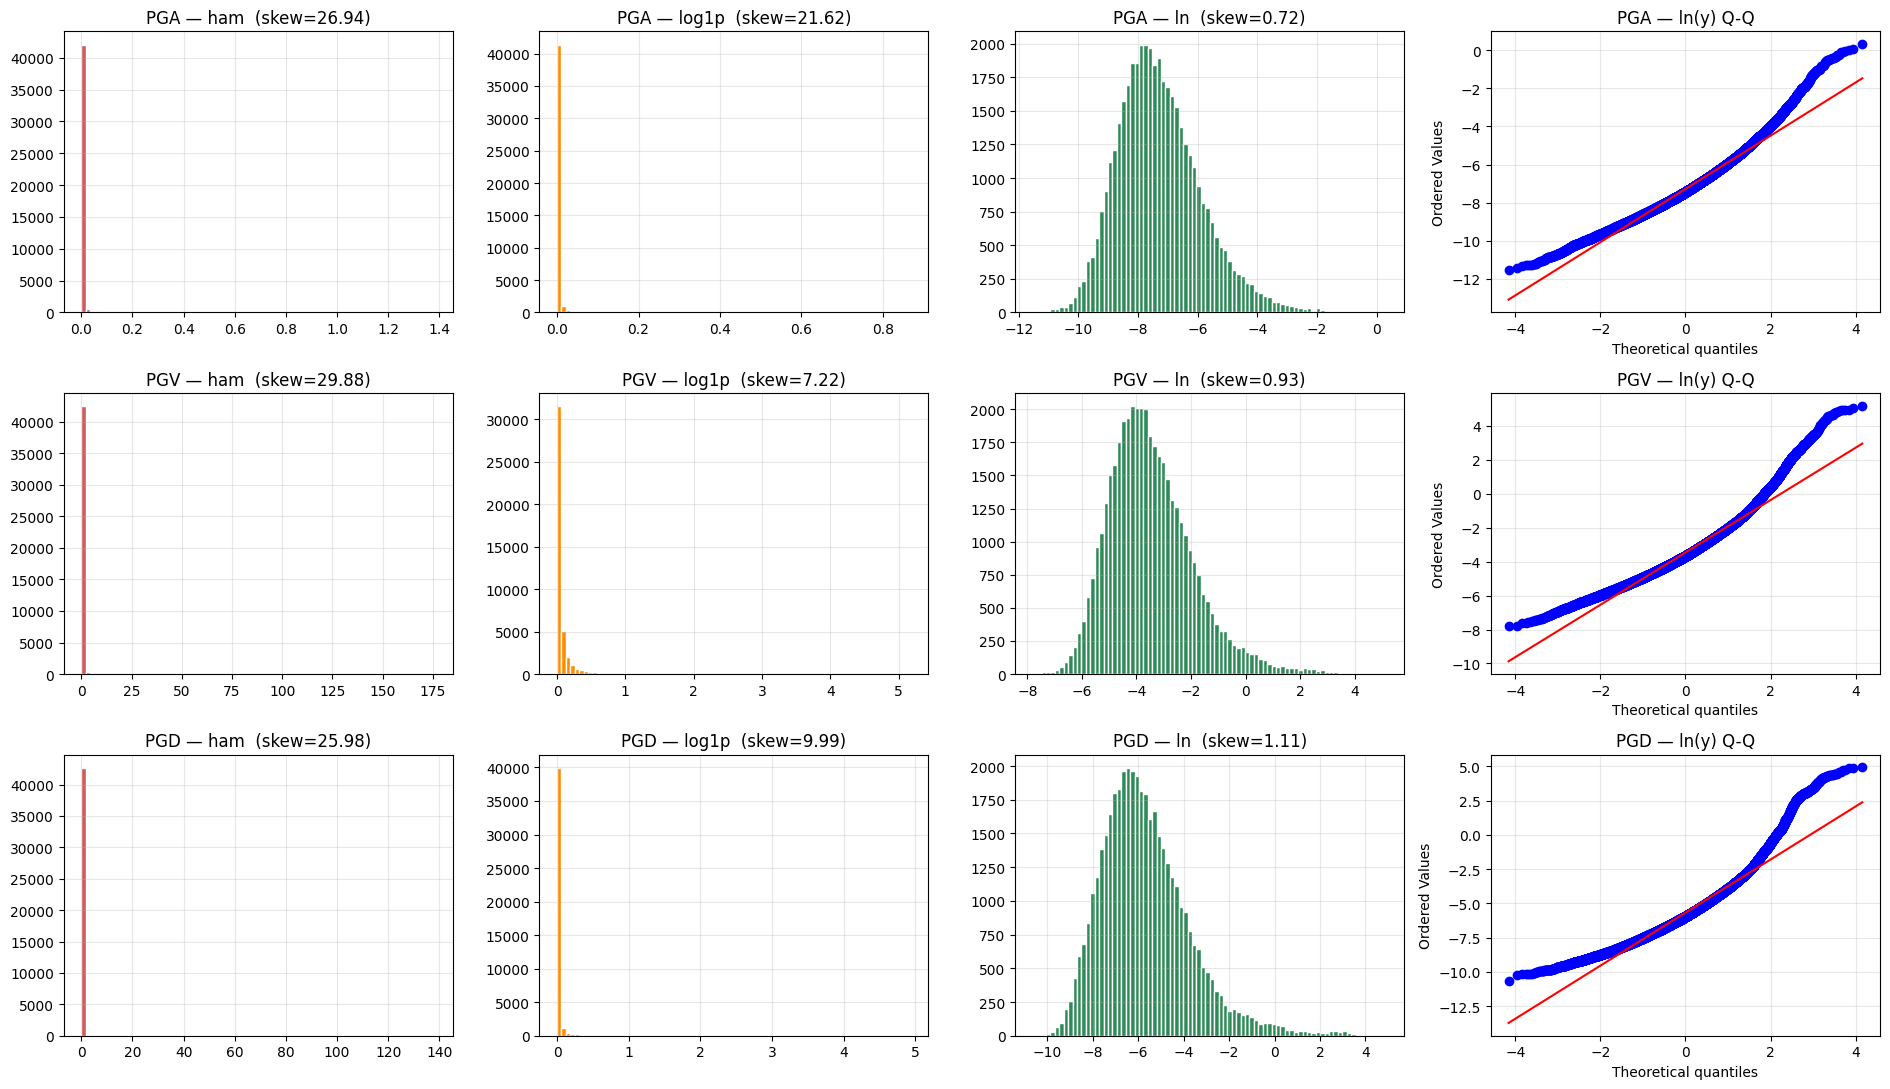

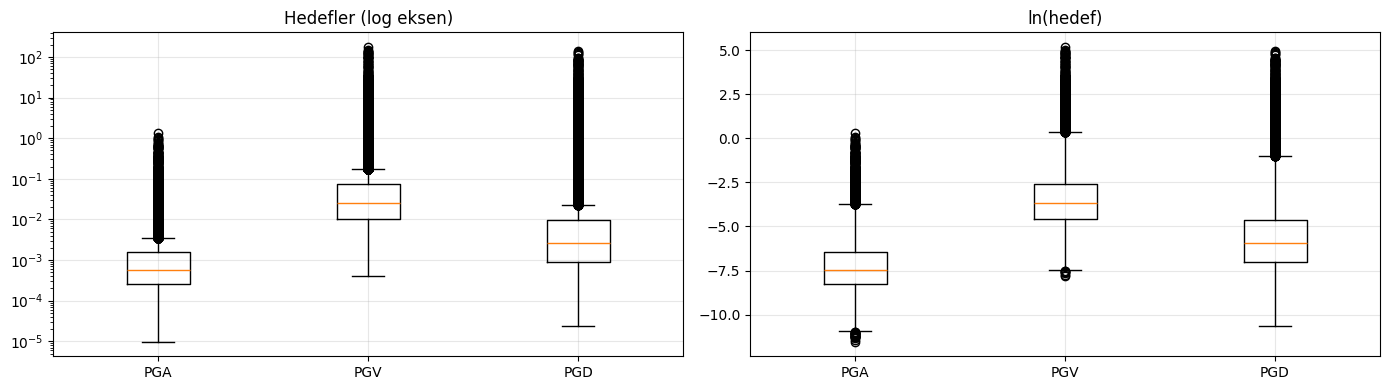

ln ölçeğinde 1.5×IQR dışı kayıt sayısı: {'PGA': 803, 'PGV': 1047, 'PGD': 1222}
Bu kayıtlar fiziksel olarak gerçek (büyük/yakın depremler) olduğundan SİLİNMEZ; ln dönüşümü etkilerini dengeler.


In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(19, 11))
for i, (h, k) in enumerate(zip(HEDEFLER, HEDEF_KISA)):
    y = df[h].values
    for j, (ad, v) in enumerate([("ham", y), ("log1p", np.log1p(y)), ("ln", np.log(y))]):
        axes[i, j].hist(v, bins=80, color=["indianred", "darkorange", "seagreen"][j], edgecolor="white")
        axes[i, j].set_title(f"{k} — {ad}  (skew={stats.skew(v):.2f})")
    stats.probplot(np.log(y), dist="norm", plot=axes[i, 3])
    axes[i, 3].set_title(f"{k} — ln(y) Q-Q")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].boxplot([df[h] for h in HEDEFLER])
axes[0].set_yscale("log"); axes[0].set_title("Hedefler (log eksen)")
axes[1].boxplot([np.log(df[h]) for h in HEDEFLER])
axes[1].set_title("ln(hedef)")
for ax in axes:
    ax.set_xticks([1, 2, 3], HEDEF_KISA)
plt.tight_layout(); plt.show()

# Aykırı değer kontrolü (yalnızca rapor): ln ölçeğinde 1.5*IQR dışındaki kayıtlar
iqr_disi = {}
for h, k in zip(HEDEFLER, HEDEF_KISA):
    l = np.log(df[h]); q1, q3 = l.quantile([0.25, 0.75])
    iqr_disi[k] = int(((l < q1 - 1.5 * (q3 - q1)) | (l > q3 + 1.5 * (q3 - q1))).sum())
print("ln ölçeğinde 1.5×IQR dışı kayıt sayısı:", iqr_disi)
print("Bu kayıtlar fiziksel olarak gerçek (büyük/yakın depremler) olduğundan SİLİNMEZ; ln dönüşümü etkilerini dengeler.")

### 6.3 Değişkenler arası ilişkiler

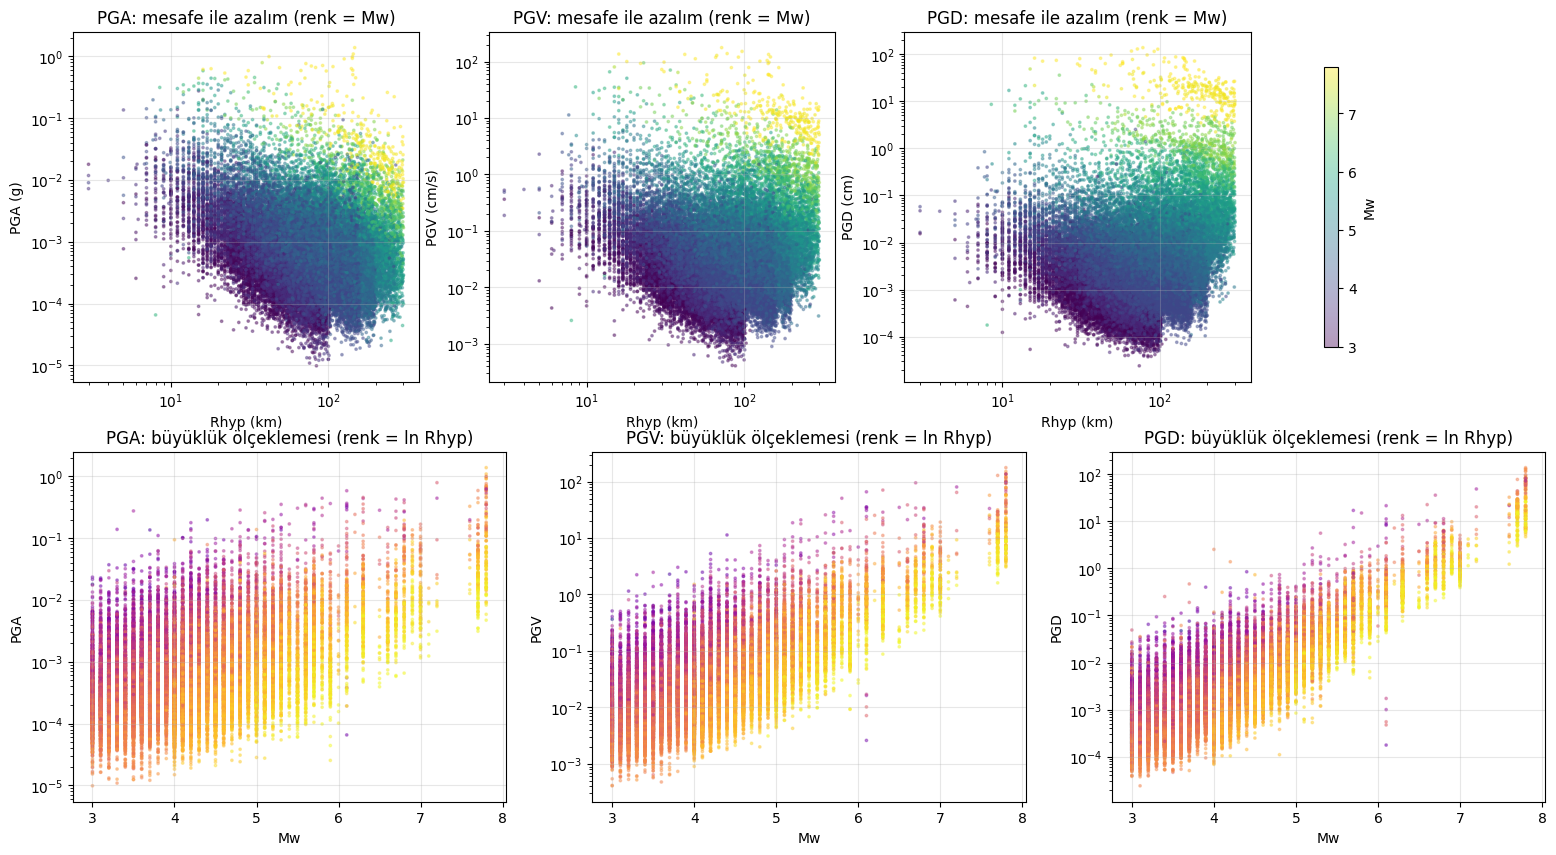

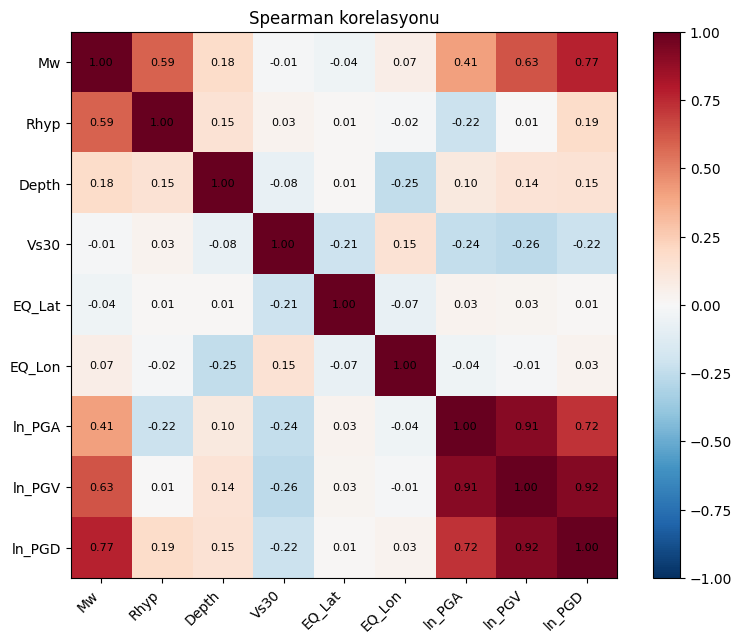

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(19, 10))
for j, (h, k) in enumerate(zip(HEDEFLER, HEDEF_KISA)):
    sc = axes[0, j].scatter(df["Rhyp"], df[h], c=df["Mw"], s=3, alpha=0.4, cmap="viridis")
    axes[0, j].set_xscale("log"); axes[0, j].set_yscale("log")
    axes[0, j].set_xlabel("Rhyp (km)"); axes[0, j].set_ylabel(f"{k} ({HEDEF_BIRIM[k]})")
    axes[0, j].set_title(f"{k}: mesafe ile azalım (renk = Mw)")
    axes[1, j].scatter(df["Mw"], df[h], c=np.log(df["Rhyp"]), s=3, alpha=0.4, cmap="plasma")
    axes[1, j].set_yscale("log"); axes[1, j].set_xlabel("Mw"); axes[1, j].set_ylabel(f"{k}")
    axes[1, j].set_title(f"{k}: büyüklük ölçeklemesi (renk = ln Rhyp)")
fig.colorbar(sc, ax=axes[0, :], shrink=0.8, label="Mw")
plt.show()

korelasyon = df[temel].copy()
for h, k in zip(HEDEFLER, HEDEF_KISA):
    korelasyon[f"ln_{k}"] = np.log(df[h])
kor = korelasyon.corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(kor, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(kor))); ax.set_xticklabels(kor.columns, rotation=45, ha="right")
ax.set_yticks(range(len(kor))); ax.set_yticklabels(kor.columns)
for a in range(len(kor)):
    for b in range(len(kor)):
        ax.text(b, a, f"{kor.iloc[a, b]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im); ax.set_title("Spearman korelasyonu"); ax.grid(False)
plt.tight_layout(); plt.show()

### 6.4 Vs30 eksikliği ve olay yapısı

In [ ]:
eksik_vs30 = df["Vs30"].isna()
karsilastirma = pd.DataFrame({
    "Vs30 bilinen": [(~eksik_vs30).sum(), df.loc[~eksik_vs30, "Mw"].mean(), df.loc[~eksik_vs30, "Rhyp"].mean(),
                     np.log(df.loc[~eksik_vs30, HEDEFLER[0]]).mean()],
    "Vs30 bilinmeyen": [eksik_vs30.sum(), df.loc[eksik_vs30, "Mw"].mean(), df.loc[eksik_vs30, "Rhyp"].mean(),
                        np.log(df.loc[eksik_vs30, HEDEFLER[0]]).mean()],
}, index=["kayıt", "ort. Mw", "ort. Rhyp", "ort. ln PGA"])
print("Vs30 eksikliği rastgele değilse, 'eksik' göstergesi modele bilgi taşır (Pipeline'da add_indicator=True).")
display(karsilastirma.round(3))

olay_boyutu = df.groupby("OLAY_ID").size()
print(f"Olay/grup sayısı: {len(olay_boyutu)}  |  olay başına kayıt: medyan={olay_boyutu.median():.0f}, "
      f"ortalama={olay_boyutu.mean():.1f}, maks={olay_boyutu.max()}")
print("Aynı depremin çok sayıda kaydı var -> rastgele ayrım olay bilgisini test setine sızdırır; olay bazlı ayrım gerekli.")

Vs30 eksikliği rastgele değilse, 'eksik' göstergesi modele bilgi taşır (Pipeline'da add_indicator=True).


,Vs30 bilinen,Vs30 bilinmeyen
kayıt,31084.000,12047.000
ort. Mw,4.206,4.194
ort. Rhyp,88.877,93.689
ort. ln PGA,-7.217,-7.448


Olay/grup sayısı: 5684  |  olay başına kayıt: medyan=3, ortalama=7.6, maks=221
Aynı depremin çok sayıda kaydı var -> rastgele ayrım olay bilgisini test setine sızdırır; olay bazlı ayrım gerekli.


## 7. Feature Engineering

Özellikler **yalnızca girdi değişkenlerinden, satır bazlı ve parametresiz** üretilir (hedeften veya
başka satırlardan bilgi kullanılmaz), bu nedenle sızıntı oluşturmaz. Aday setler yer hareketi tahmin
denklemlerinin (GMPE) fiziksel yapısına dayanır:

`ln Y ≈ c0 + c1·Mw + c2·Mw² + (c3 + c4·Mw)·ln R + c5·R + c6·ln Vs30 + c7·Depth`

- `Mw²`: büyüklük ölçeklemesinin doygunluğu
- `ln Rhyp`: geometrik yayılım; `Mw·ln Rhyp`: büyüklüğe bağlı geometrik yayılım
- `Rhyp` (doğrusal): anelastik sönümlenme
- `ln Vs30`: zemin büyütmesi; eksikse Pipeline'da doldurulur + eksiklik göstergesi eklenir

Hangi setin kullanılacağı **Bölüm 10.3'te CV ile (ablation)** belirlenir.

In [ ]:
GIRDI_SUTUNLARI = ["Mw", "Rhyp", "Depth", "Vs30"] + (["EQ_Lat", "EQ_Lon"] if KOORDINAT_VAR else [])


def ozellikleri_hesapla(X):
    """Ham girdilerden tüm aday özellikleri üretir (satır bazlı, parametresiz)."""
    Mw, Rhyp, Depth, Vs30 = X["Mw"], X["Rhyp"], X["Depth"], X["Vs30"]
    R = Rhyp.clip(lower=1.0)  # ln(0) önlemi (Rhyp >= 1 km)
    o = pd.DataFrame(index=X.index)
    o["Mw"], o["Rhyp"], o["Depth"], o["Vs30"] = Mw, Rhyp, Depth, Vs30
    # Fiziksel (GMPE tabanlı) özellikler
    o["Mw2"] = Mw ** 2
    o["ln_Rhyp"] = np.log(R)
    o["Mw_x_lnRhyp"] = Mw * np.log(R)
    o["Depth2"] = Depth ** 2
    o["ln_Vs30"] = np.log(Vs30)
    # Mevcut notebook'taki özellikler (baseline için)
    o["R_epi"] = np.sqrt(np.maximum(0, Rhyp ** 2 - Depth ** 2))
    o["Log_Vs30"] = np.log1p(Vs30)
    o["Log_Rhyp"] = np.log1p(Rhyp)
    o["Mw_x_Rhyp"] = Mw * Rhyp
    o["Mw_x_Depth"] = Mw * Depth
    o["Log_Depth"] = np.log1p(Depth)
    o["Log_Mw"] = np.log1p(Mw)
    if KOORDINAT_VAR:
        o["EQ_Lat"], o["EQ_Lon"] = X["EQ_Lat"], X["EQ_Lon"]
    return o


KOORD = ["EQ_Lat", "EQ_Lon"] if KOORDINAT_VAR else []
OZELLIK_SETLERI = {
    "ham": ["Mw", "Rhyp", "Depth", "Vs30"],
    "notebook": ["Depth", "Mw", "Rhyp", "Vs30", "R_epi", "Log_Vs30", "Log_Rhyp",
                 "Mw_x_Rhyp", "Mw_x_Depth", "Log_Depth", "Log_Mw"] + KOORD,
    "fiziksel": ["Mw", "Mw2", "ln_Rhyp", "Mw_x_lnRhyp", "Rhyp", "Depth", "ln_Vs30"],
    "fiziksel_genis": ["Mw", "Mw2", "ln_Rhyp", "Mw_x_lnRhyp", "Rhyp", "Depth", "Depth2",
                       "Mw_x_Depth", "R_epi", "ln_Vs30"],
}
if KOORDINAT_VAR:
    OZELLIK_SETLERI["fiziksel+koordinat"] = OZELLIK_SETLERI["fiziksel"] + KOORD


class DepremOzellikleri(BaseEstimator, TransformerMixin):
    """Pipeline adımı: ham girdilerden seçilen özellik setini üretir (fit'te öğrenilen parametre yok)."""

    def __init__(self, ozellik_seti="fiziksel"):
        self.ozellik_seti = ozellik_seti

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X if isinstance(X, pd.DataFrame) else pd.DataFrame(X, columns=GIRDI_SUTUNLARI)
        return ozellikleri_hesapla(X)[OZELLIK_SETLERI[self.ozellik_seti]]

    def get_feature_names_out(self, input_features=None):
        return np.array(OZELLIK_SETLERI[self.ozellik_seti], dtype=object)


for ad, s in OZELLIK_SETLERI.items():
    print(f"{ad:20s} ({len(s):2d}): {s}")

ham                  ( 4): ['Mw', 'Rhyp', 'Depth', 'Vs30']
notebook             (13): ['Depth', 'Mw', 'Rhyp', 'Vs30', 'R_epi', 'Log_Vs30', 'Log_Rhyp', 'Mw_x_Rhyp', 'Mw_x_Depth', 'Log_Depth', 'Log_Mw', 'EQ_Lat', 'EQ_Lon']
fiziksel             ( 7): ['Mw', 'Mw2', 'ln_Rhyp', 'Mw_x_lnRhyp', 'Rhyp', 'Depth', 'ln_Vs30']
fiziksel_genis       (10): ['Mw', 'Mw2', 'ln_Rhyp', 'Mw_x_lnRhyp', 'Rhyp', 'Depth', 'Depth2', 'Mw_x_Depth', 'R_epi', 'ln_Vs30']
fiziksel+koordinat   ( 9): ['Mw', 'Mw2', 'ln_Rhyp', 'Mw_x_lnRhyp', 'Rhyp', 'Depth', 'ln_Vs30', 'EQ_Lat', 'EQ_Lon']


## 8. Train/Test Split (olay bazlı)

`GroupShuffleSplit` ile olayların %15'i **bağımsız test seti** olarak ayrılır; aynı depremin kayıtları
iki sete dağılmaz. Eğitim setinde 5-katlı `GroupKFold` katmanları bir kez oluşturulur ve tüm
karşılaştırmalarda **aynı katmanlar** kullanılır. **Test seti Bölüm 14'e kadar hiç kullanılmaz.**

In [ ]:
X_tum = df[GIRDI_SUTUNLARI]
Y_tum = df[HEDEFLER].values
gruplar_tum = df["OLAY_ID"].values

gss = GroupShuffleSplit(n_splits=1, test_size=TEST_ORANI, random_state=RANDOM_STATE)
tr_idx, te_idx = next(gss.split(X_tum, Y_tum, gruplar_tum))

X_train, X_test = X_tum.iloc[tr_idx].reset_index(drop=True), X_tum.iloc[te_idx].reset_index(drop=True)
Y_train, Y_test = Y_tum[tr_idx], Y_tum[te_idx]
g_train, g_test = gruplar_tum[tr_idx], gruplar_tum[te_idx]

# Sızıntı kontrolleri
assert not set(g_train) & set(g_test), "Aynı olay hem train hem testte!"
ortak = pd.merge(df.iloc[tr_idx][GIRDI_SUTUNLARI + HEDEFLER], df.iloc[te_idx][GIRDI_SUTUNLARI + HEDEFLER], how="inner")
assert len(ortak) == 0, "Train ve testte birebir aynı kayıt var!"

try:
    gkf = GroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)
except TypeError:  # scikit-learn < 1.6
    gkf = GroupKFold(n_splits=N_FOLDS)
CV_FOLDS = list(gkf.split(X_train, Y_train, g_train))


def set_ozeti(X, Y, g):
    return {"kayıt": len(X), "olay": len(np.unique(g)), "ort. Mw": X["Mw"].mean(),
            "ort. Rhyp": X["Rhyp"].mean(), "Vs30 eksik %": 100 * X["Vs30"].isna().mean(),
            "ort. ln PGA": np.log(Y[:, 0]).mean()}

print(pd.DataFrame({"Train": set_ozeti(X_train, Y_train, g_train),
                    "Test": set_ozeti(X_test, Y_test, g_test)}).round(3))
print(f"\nTest oranı (kayıt): {len(X_test) / len(X_tum):.1%}")
print("CV katman boyutları (val):", [len(v) for _, v in CV_FOLDS])

                  Train      Test
kayıt         36622.000  6509.000
olay           4831.000   853.000
ort. Mw           4.213     4.145
ort. Rhyp        90.508    88.607
Vs30 eksik %     27.989    27.608
ort. ln PGA      -7.279    -7.298

Test oranı (kayıt): 15.1%
CV katman boyutları (val): [7302, 7738, 7032, 7833, 6717]


## 9. Preprocessing Pipeline

Her model şu yapıda kurulur:

```
TransformedTargetRegressor(func=ln, inverse=exp)
 └─ Pipeline: DepremOzellikleri → SimpleImputer(median, add_indicator) → [StandardScaler] → Model
```

`fit` çağrıldığında imputer medyanı ve scaler parametreleri **yalnızca o anki eğitim verisinden**
öğrenilir; CV'nin her katmanında yeniden fit edilir. Ölçekleme yalnızca lineer modellerde uygulanır
(ağaç modelleri ölçekten bağımsızdır; ölçeksiz tutmak SHAP grafiklerini fiziksel birimlerde okunur kılar).

**Metrikler:** Birincil metrikler ln ölçeğindedir (yer hareketi modellerinde standart; `RMSE_ln` ≈ σ,
`exp(σ)` hatanın çarpan cinsinden büyüklüğü). Orijinal ölçekte R² ve MAPE de raporlanır. Farklı birimli
hedeflerin RMSE/MAE'si **ortalanmaz**; bunlar Bölüm 14'te hedef bazında verilir.

In [ ]:
DONUSUMLER = {"ham": (None, None), "log1p": (np.log1p, np.expm1), "ln": (np.log, np.exp)}


def pipeline_kur(estimator, ozellik_seti="fiziksel", donusum="ln", olcekle=False):
    adimlar = [("ozellik", DepremOzellikleri(ozellik_seti)),
               ("eksik", SimpleImputer(strategy="median", add_indicator=True))]
    if olcekle:
        adimlar.append(("olcek", StandardScaler()))
    adimlar.append(("model", estimator))
    pipe = Pipeline(adimlar).set_output(transform="pandas")
    f, fi = DONUSUMLER[donusum]
    return TransformedTargetRegressor(regressor=pipe, func=f, inverse_func=fi, check_inverse=False)


def _ln(Y):
    return np.log(np.clip(Y, EPS, None))


def rmse_ln(Y_true, Y_pred):
    return float(np.mean(np.sqrt(np.mean((_ln(Y_true) - _ln(Y_pred)) ** 2, axis=0))))


def metrikler(Y_true, Y_pred):
    """3 hedefin ortalaması (her hedef eşit ağırlıklı). Tahminler orijinal ölçektedir."""
    lt, lp = _ln(Y_true), _ln(Y_pred)
    return {
        "R2_ln": r2_score(lt, lp),
        "RMSE_ln": rmse_ln(Y_true, Y_pred),
        "MAE_ln": mean_absolute_error(lt, lp),
        "MedAE_ln": median_absolute_error(lt, lp),
        "EV_ln": explained_variance_score(lt, lp),
        "R2_orij": r2_score(Y_true, Y_pred),
        "MAPE_orij_%": 100 * mean_absolute_percentage_error(Y_true, Y_pred),
    }


def hedef_bazli_metrikler(Y_true, Y_pred):
    satirlar = []
    for i, k in enumerate(HEDEF_KISA):
        yt, yp = Y_true[:, i], np.clip(Y_pred[:, i], EPS, None)
        satirlar.append({
            "Hedef": f"{k} ({HEDEF_BIRIM[k]})",
            "R2_ln": r2_score(np.log(yt), np.log(yp)),
            "RMSE_ln (σ)": float(np.sqrt(mean_squared_error(np.log(yt), np.log(yp)))),
            "MAE_ln": mean_absolute_error(np.log(yt), np.log(yp)),
            "R2_orij": r2_score(yt, yp),
            "RMSE_orij": float(np.sqrt(mean_squared_error(yt, yp))),
            "MAE_orij": mean_absolute_error(yt, yp),
            "MedAE_orij": median_absolute_error(yt, yp),
            "MAPE_orij_%": 100 * mean_absolute_percentage_error(yt, yp),
        })
    return pd.DataFrame(satirlar).set_index("Hedef")


def cv_degerlendir(model_fn, X=None, Y=None, maske=None, egitim_skoru=True, trial=None):
    """Sabit CV_FOLDS üzerinde değerlendirme. maske: katmanlarda kullanılacak satırlar (bool dizi)."""
    X = X_train if X is None else X
    Y = Y_train if Y is None else Y
    satirlar = []
    for k, (tr, va) in enumerate(CV_FOLDS):
        if maske is not None:
            tr, va = tr[maske[tr]], va[maske[va]]
        m = model_fn()
        t0 = time.time()
        m.fit(X.iloc[tr], Y[tr])
        sat = {"fold": k, "sure_sn": time.time() - t0}
        sat.update({f"val_{a}": v for a, v in metrikler(Y[va], m.predict(X.iloc[va])).items()})
        if egitim_skoru:
            sat.update({f"train_{a}": v for a, v in metrikler(Y[tr], m.predict(X.iloc[tr])).items()})
        satirlar.append(sat)
        if trial is not None:
            trial.report(float(np.mean([s["val_RMSE_ln"] for s in satirlar])), k)
            if trial.should_prune():
                raise optuna.TrialPruned()
    return pd.DataFrame(satirlar)


def cv_ozet(ad, f):
    o = {"Model": ad,
         "CV R2_ln": f["val_R2_ln"].mean(), "CV R2_ln std": f["val_R2_ln"].std(),
         "CV RMSE_ln": f["val_RMSE_ln"].mean(), "CV RMSE_ln std": f["val_RMSE_ln"].std(),
         "CV MAE_ln": f["val_MAE_ln"].mean(), "CV R2_orij": f["val_R2_orij"].mean(),
         "CV MAPE_%": f["val_MAPE_orij_%"].mean()}
    if "train_R2_ln" in f:
        o.update({"Train R2_ln": f["train_R2_ln"].mean(), "Train RMSE_ln": f["train_RMSE_ln"].mean(),
                  "Fark R2 (train-CV)": f["train_R2_ln"].mean() - f["val_R2_ln"].mean()})
    o["Süre/fold (sn)"] = f["sure_sn"].mean()
    return o


CV_KAYITLARI = {}  # model adı -> fold bazlı sonuç tablosu (kararlılık analizi için)

## 10. Baseline Models

### 10.1 Mevcut yaklaşımın (deprem_model-2.ipynb) olay bazlı CV ile yeniden değerlendirilmesi

Mevcut notebook'un en iyi modeli birebir kurulur: aynı özellikler, `log1p` hedef dönüşümü, aynı
LightGBM hiperparametreleri ve Vs30 bilinmeyen satırların çıkarılması. Tek fark, değerlendirmenin
olay bazlı CV ile yapılmasıdır.

In [ ]:
def mevcut_model_kur():
    if HAS_LGBM:
        est = MultiOutputRegressor(LGBMRegressor(
            n_estimators=500, max_depth=-1, learning_rate=0.03, subsample=0.8, colsample_bytree=0.8,
            random_state=RANDOM_STATE, n_jobs=-1, verbose=-1))
    else:
        est = MultiOutputRegressor(HistGradientBoostingRegressor(random_state=RANDOM_STATE))
    return pipeline_kur(est, "notebook", "log1p", olcekle=True)


VS30_BILINEN_TRAIN = X_train["Vs30"].notna().values
f = cv_degerlendir(mevcut_model_kur, maske=VS30_BILINEN_TRAIN)
CV_KAYITLARI["Mevcut yaklaşım (notebook)"] = f
mevcut_cv = cv_ozet("Mevcut yaklaşım (notebook)", f)
pd.DataFrame([mevcut_cv]).set_index("Model").round(4)

,CV R2_ln,CV R2_ln std,CV RMSE_ln,CV RMSE_ln std,CV MAE_ln,CV R2_orij,CV MAPE_%,Train R2_ln,Train RMSE_ln,Fark R2 (train-CV),Süre/fold (sn)
Model,,,,,,,,,,,
Mevcut yaklaşım (notebook),-0.258,0.4275,1.7206,0.2057,0.8702,0.3053,212.5106,0.2528,1.4323,0.5108,5.9529


### 10.2 Hedef dönüşümü karşılaştırması (ham / log1p / ln)

Dönüşümün etkisini izole etmek için model (LightGBM, mevcut hiperparametreler) ve özellikler
(`notebook` seti) sabit tutulur; yalnızca hedef dönüşümü değişir. Tüm metrikler aynı şekilde,
orijinal ölçekteki tahminlerden hesaplanır.

In [ ]:
def lgbm_varsayilan():
    if HAS_LGBM:
        return MultiOutputRegressor(LGBMRegressor(
            n_estimators=500, learning_rate=0.03, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
            random_state=RANDOM_STATE, n_jobs=-1, verbose=-1))
    return MultiOutputRegressor(HistGradientBoostingRegressor(random_state=RANDOM_STATE))


donusum_sonuclari = []
for donusum in ["ham", "log1p", "ln"]:
    f = cv_degerlendir(lambda: pipeline_kur(lgbm_varsayilan(), "notebook", donusum), egitim_skoru=False)
    donusum_sonuclari.append(cv_ozet(f"LightGBM | notebook | {donusum}", f))
donusum_df = pd.DataFrame(donusum_sonuclari).set_index("Model")

EN_IYI_DONUSUM = ["ham", "log1p", "ln"][int(np.argmin(donusum_df["CV RMSE_ln"].values))]
print(f"Seçilen hedef dönüşümü (CV RMSE_ln'e göre): {EN_IYI_DONUSUM}")
donusum_df.round(4)

Seçilen hedef dönüşümü (CV RMSE_ln'e göre): ln


,CV R2_ln,CV R2_ln std,CV RMSE_ln,CV RMSE_ln std,CV MAE_ln,CV R2_orij,CV MAPE_%,Süre/fold (sn)
Model,,,,,,,,
LightGBM | notebook | ham,-1.3037,0.8403,2.4341,0.2857,1.1876,0.1929,305.0922,6.4356
LightGBM | notebook | log1p,0.2155,0.2698,1.3349,0.1546,0.7907,0.3454,190.8439,5.5614
LightGBM | notebook | ln,0.8048,0.0372,0.6997,0.0186,0.5365,0.4477,99.8919,6.5753


### 10.3 Özellik seti ablation çalışması

Hedef dönüşümü sabitlenerek her özellik seti, bir ağaç modeli (LightGBM) ve bir lineer model (Ridge)
ile CV'de değerlendirilir. Ağaç modelleri etkileşimleri kendileri öğrenebildiği, lineer modeller ise
öğrenemediği için özellik seti **model ailesine göre ayrı** seçilir: ağaç modelleri için LightGBM,
lineer modeller için Ridge sonuçları kullanılır. Seçim kuralı: CV RMSE_ln değeri en iyiye
**1 standart hata** kadar yakın olan setlerden **en az özellikli** olanı (gereksiz karmaşıklıktan kaçınmak için).

In [20]:
ablation = []
for set_adi in OZELLIK_SETLERI:
    for model_adi, fn, olc in [("LightGBM", lgbm_varsayilan, False), ("Ridge", lambda: Ridge(alpha=1.0), True)]:
        f = cv_degerlendir(lambda: pipeline_kur(fn(), set_adi, EN_IYI_DONUSUM, olcekle=olc), egitim_skoru=False)
        o = cv_ozet(model_adi, f)
        o.update({"Özellik seti": set_adi, "Özellik sayısı": len(OZELLIK_SETLERI[set_adi])})
        ablation.append(o)
ablation_df = pd.DataFrame(ablation)

def set_sec(model_adi):
    t = ablation_df[ablation_df["Model"] == model_adi].copy()
    t["SE"] = t["CV RMSE_ln std"] / np.sqrt(N_FOLDS)
    en_iyi = t.loc[t["CV RMSE_ln"].idxmin()]
    adaylar = t[t["CV RMSE_ln"] <= en_iyi["CV RMSE_ln"] + en_iyi["SE"]]
    secilen = adaylar.sort_values(["Özellik sayısı", "CV RMSE_ln"]).iloc[0]["Özellik seti"]
    print(f"{model_adi:9s} en düşük CV RMSE_ln: {en_iyi['Özellik seti']} ({en_iyi['CV RMSE_ln']:.4f} ± SE "
          f"{en_iyi['SE']:.4f})  ->  1-SE ile seçilen: {secilen} {OZELLIK_SETLERI[secilen]}")
    return secilen


SET_AGAC = set_sec("LightGBM")
SET_LINEER = set_sec("Ridge")


def model_seti(olcekle):
    """Lineer (ölçeklenen) modeller için lineer set, ağaç modelleri için ağaç seti."""
    return SET_LINEER if olcekle else SET_AGAC

pivot = ablation_df.pivot(index="Özellik seti", columns="Model", values=["CV RMSE_ln", "CV R2_ln"])
pivot.round(4)

LightGBM  en düşük CV RMSE_ln: fiziksel+koordinat (0.6985 ± SE 0.0084)  ->  1-SE ile seçilen: fiziksel+koordinat ['Mw', 'Mw2', 'ln_Rhyp', 'Mw_x_lnRhyp', 'Rhyp', 'Depth', 'ln_Vs30', 'EQ_Lat', 'EQ_Lon']
Ridge     en düşük CV RMSE_ln: notebook (0.7660 ± SE 0.0071)  ->  1-SE ile seçilen: fiziksel+koordinat ['Mw', 'Mw2', 'ln_Rhyp', 'Mw_x_lnRhyp', 'Rhyp', 'Depth', 'ln_Vs30', 'EQ_Lat', 'EQ_Lon']


CV RMSE_ln         CV R2_ln        
Model                LightGBM   Ridge LightGBM   Ridge
Özellik seti                                          
fiziksel               0.7385  0.7748   0.7813  0.7577
fiziksel+koordinat     0.6985  0.7690   0.8053  0.7619
fiziksel_genis         0.7451  0.7740   0.7776  0.7582
ham                    0.7380  0.8721   0.7816  0.6965
notebook               0.6997  0.7660   0.8048  0.7639

### 10.4 Temel (varsayılan hiperparametreli) model karşılaştırması

Tüm modeller aynı hedef dönüşümü ve aynı CV katmanlarıyla değerlendirilir; özellik seti model
ailesine göre 10.3'te seçilen settir (ağaç / lineer).
Çok çıktıyı doğal desteklemeyen modeller `MultiOutputRegressor` ile sarmalanır.

In [21]:
MODEL_KATALOGU = {
    "Linear Regression": dict(kur=lambda: LinearRegression(), olcekle=True),
    "Ridge": dict(kur=lambda: Ridge(alpha=1.0), olcekle=True),
    "Lasso": dict(kur=lambda: Lasso(alpha=1e-3, max_iter=20000), olcekle=True),
    "Elastic Net": dict(kur=lambda: ElasticNet(alpha=1e-3, l1_ratio=0.5, max_iter=20000), olcekle=True),
    "Random Forest": dict(kur=lambda: RandomForestRegressor(
        n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE), olcekle=False),
    "Extra Trees": dict(kur=lambda: ExtraTreesRegressor(
        n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE), olcekle=False),
    "Gradient Boosting": dict(kur=lambda: MultiOutputRegressor(GradientBoostingRegressor(
        n_estimators=300, max_depth=3, learning_rate=0.05, random_state=RANDOM_STATE)), olcekle=False),
    "HistGradientBoosting": dict(kur=lambda: MultiOutputRegressor(HistGradientBoostingRegressor(
        max_iter=500, learning_rate=0.05, random_state=RANDOM_STATE)), olcekle=False),
}
if HAS_XGB:
    MODEL_KATALOGU["XGBoost"] = dict(kur=lambda: XGBRegressor(
        n_estimators=500, max_depth=6, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
        tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE), olcekle=False)
if HAS_LGBM:
    MODEL_KATALOGU["LightGBM"] = dict(kur=lgbm_varsayilan, olcekle=False)
if HAS_CAT:
    MODEL_KATALOGU["CatBoost"] = dict(kur=lambda: CatBoostRegressor(
        iterations=1000, depth=6, learning_rate=0.05, loss_function="MultiRMSE",
        random_seed=RANDOM_STATE, verbose=0, thread_count=-1, allow_writing_files=False), olcekle=False)

temel_sonuclar = []
for ad, spec in MODEL_KATALOGU.items():
    t0 = time.time()
    f = cv_degerlendir(lambda: pipeline_kur(spec["kur"](), model_seti(spec["olcekle"]), EN_IYI_DONUSUM,
                                            spec["olcekle"]))
    CV_KAYITLARI[ad] = f
    temel_sonuclar.append(cv_ozet(ad, f))
    print(f"{ad:22s} CV RMSE_ln={f['val_RMSE_ln'].mean():.4f}  CV R2_ln={f['val_R2_ln'].mean():.4f}  "
          f"({time.time() - t0:.0f} sn)")

temel_df = pd.DataFrame(temel_sonuclar).set_index("Model").sort_values("CV RMSE_ln")
temel_df.round(4)

Linear Regression      CV RMSE_ln=0.7690  CV R2_ln=0.7619  (1 sn)
Ridge                  CV RMSE_ln=0.7690  CV R2_ln=0.7619  (1 sn)
Lasso                  CV RMSE_ln=0.7689  CV R2_ln=0.7619  (7 sn)
Elastic Net            CV RMSE_ln=0.7690  CV R2_ln=0.7619  (3 sn)
Random Forest          CV RMSE_ln=0.7400  CV R2_ln=0.7806  (252 sn)
Extra Trees            CV RMSE_ln=0.7607  CV R2_ln=0.7677  (108 sn)
Gradient Boosting      CV RMSE_ln=0.7376  CV R2_ln=0.7809  (246 sn)
HistGradientBoosting   CV RMSE_ln=0.6987  CV R2_ln=0.8055  (61 sn)
XGBoost                CV RMSE_ln=0.6930  CV R2_ln=0.8092  (37 sn)
LightGBM               CV RMSE_ln=0.6985  CV R2_ln=0.8053  (42 sn)
CatBoost               CV RMSE_ln=0.6960  CV R2_ln=0.8068  (72 sn)


,CV R2_ln,CV R2_ln std,CV RMSE_ln,CV RMSE_ln std,CV MAE_ln,CV R2_orij,CV MAPE_%,Train R2_ln,Train RMSE_ln,Fark R2 (train-CV),Süre/fold (sn)
Model,,,,,,,,,,,
XGBoost,0.8092,0.0351,0.6930,0.0162,0.5299,0.4200,95.8831,0.8943,0.5242,0.0851,6.0133
CatBoost,0.8068,0.0364,0.6960,0.0201,0.5332,0.5210,98.5715,0.8570,0.6101,0.0501,14.2784
LightGBM,0.8053,0.0373,0.6985,0.0187,0.5351,0.4355,109.0466,0.8652,0.5923,0.0599,5.2360
HistGradientBoosting,0.8055,0.0381,0.6987,0.0167,0.5354,0.4370,114.9783,0.8787,0.5620,0.0731,7.6042
Gradient Boosting,0.7809,0.0425,0.7376,0.0147,0.5699,0.3481,111.0285,0.8135,0.6948,0.0326,48.6132
Random Forest,0.7806,0.0405,0.7400,0.0161,0.5694,0.2215,128.8974,0.9481,0.3671,0.1675,48.3702
Extra Trees,0.7677,0.0444,0.7607,0.0180,0.5853,0.4160,123.2212,0.9614,0.3166,0.1937,19.1820
Lasso,0.7619,0.0447,0.7689,0.0137,0.5974,0.1232,174.5917,0.7728,0.7664,0.0109,1.3293
Elastic Net,0.7619,0.0447,0.7690,0.0135,0.5975,0.0679,168.7304,0.7729,0.7663,0.0110,0.5509


## 11. Hyperparameter Optimization

Optuna (TPE örnekleyici, sabit tohum) ile **yalnızca eğitim setindeki aynı 5 CV katmanı** üzerinde
arama yapılır; amaç fonksiyonu ortalama CV RMSE_ln'dir. Kötü denemeler `MedianPruner` ile erken
kesilir. Aranan modeller: XGBoost, Random Forest, Extra Trees (istenen) + temel karşılaştırmada en iyi
2 model. Test seti bu aşamada **kullanılmaz**.

In [22]:
def xgb_uzay(t):
    return XGBRegressor(
        n_estimators=t.suggest_int("n_estimators", 200, 1500, step=100),
        max_depth=t.suggest_int("max_depth", 3, 10),
        learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
        subsample=t.suggest_float("subsample", 0.5, 1.0),
        colsample_bytree=t.suggest_float("colsample_bytree", 0.5, 1.0),
        min_child_weight=t.suggest_float("min_child_weight", 1.0, 50.0, log=True),
        reg_alpha=t.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        reg_lambda=t.suggest_float("reg_lambda", 1e-3, 50.0, log=True),
        tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE)


def _orman_parametreleri(t):
    return dict(
        n_estimators=t.suggest_int("n_estimators", 200, 600, step=100),
        max_depth=t.suggest_categorical("max_depth", [None, 10, 15, 20, 30]),
        min_samples_split=t.suggest_int("min_samples_split", 2, 20),
        min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 20),
        max_features=t.suggest_float("max_features", 0.2, 1.0),
        n_jobs=-1, random_state=RANDOM_STATE)


def rf_uzay(t):
    return RandomForestRegressor(**_orman_parametreleri(t))


def et_uzay(t):
    return ExtraTreesRegressor(**_orman_parametreleri(t))


def lgbm_uzay(t):
    return MultiOutputRegressor(LGBMRegressor(
        n_estimators=t.suggest_int("n_estimators", 200, 2000, step=100),
        learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
        num_leaves=t.suggest_int("num_leaves", 15, 255, log=True),
        max_depth=t.suggest_categorical("max_depth", [-1, 4, 6, 8, 10, 12]),
        min_child_samples=t.suggest_int("min_child_samples", 5, 100, log=True),
        subsample=t.suggest_float("subsample", 0.5, 1.0), subsample_freq=1,
        colsample_bytree=t.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_alpha=t.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
        reg_lambda=t.suggest_float("reg_lambda", 1e-3, 50.0, log=True),
        random_state=RANDOM_STATE, n_jobs=-1, verbose=-1))


def cat_uzay(t):
    return CatBoostRegressor(
        iterations=t.suggest_int("iterations", 300, 1500, step=100),
        depth=t.suggest_int("depth", 4, 8),
        learning_rate=t.suggest_float("learning_rate", 0.02, 0.2, log=True),
        l2_leaf_reg=t.suggest_float("l2_leaf_reg", 1.0, 30.0, log=True),
        random_strength=t.suggest_float("random_strength", 0.1, 10.0, log=True),
        bagging_temperature=t.suggest_float("bagging_temperature", 0.0, 1.0),
        loss_function="MultiRMSE", random_seed=RANDOM_STATE, verbose=0, thread_count=-1,
        allow_writing_files=False)


def hgb_uzay(t):
    return MultiOutputRegressor(HistGradientBoostingRegressor(
        max_iter=t.suggest_int("max_iter", 200, 1000, step=100),
        learning_rate=t.suggest_float("learning_rate", 0.01, 0.2, log=True),
        max_leaf_nodes=t.suggest_int("max_leaf_nodes", 15, 127, log=True),
        min_samples_leaf=t.suggest_int("min_samples_leaf", 5, 100, log=True),
        l2_regularization=t.suggest_float("l2_regularization", 1e-4, 10.0, log=True),
        random_state=RANDOM_STATE))


def gb_uzay(t):
    return MultiOutputRegressor(GradientBoostingRegressor(
        n_estimators=t.suggest_int("n_estimators", 100, 600, step=50),
        max_depth=t.suggest_int("max_depth", 2, 6),
        learning_rate=t.suggest_float("learning_rate", 0.02, 0.2, log=True),
        subsample=t.suggest_float("subsample", 0.6, 1.0),
        min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 50, log=True),
        random_state=RANDOM_STATE))


ARAMA_UZAYLARI = {"Random Forest": rf_uzay, "Extra Trees": et_uzay,
                  "HistGradientBoosting": hgb_uzay, "Gradient Boosting": gb_uzay}
if HAS_XGB:
    ARAMA_UZAYLARI["XGBoost"] = xgb_uzay
if HAS_LGBM:
    ARAMA_UZAYLARI["LightGBM"] = lgbm_uzay
if HAS_CAT:
    ARAMA_UZAYLARI["CatBoost"] = cat_uzay

istenen = [m for m in ["XGBoost", "Random Forest", "Extra Trees"] if m in ARAMA_UZAYLARI]
en_iyi_temel = [m for m in temel_df.index if m in ARAMA_UZAYLARI and m not in istenen][:2]
OPTIMIZE_EDILECEK = istenen + en_iyi_temel
print("Optimize edilecek modeller:", OPTIMIZE_EDILECEK)

Optimize edilecek modeller: ['XGBoost', 'Random Forest', 'Extra Trees', 'CatBoost', 'LightGBM']


In [23]:
optuna_sonuclari = {}
for ad in OPTIMIZE_EDILECEK:
    uzay = ARAMA_UZAYLARI[ad]

    def amac(trial, uzay=uzay):
        f = cv_degerlendir(lambda: pipeline_kur(uzay(trial), SET_AGAC, EN_IYI_DONUSUM),
                           egitim_skoru=False, trial=trial)
        return float(f["val_RMSE_ln"].mean())

    study = optuna.create_study(
        direction="minimize", study_name=ad,
        sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1))
    t0 = time.time()
    study.optimize(amac, n_trials=N_TRIALS.get(ad, 15))
    tamam = sum(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials)
    optuna_sonuclari[ad] = study
    print(f"{ad:22s} en iyi CV RMSE_ln={study.best_value:.4f}  (tamamlanan {tamam}/{len(study.trials)} deneme, "
          f"{time.time() - t0:.0f} sn)")
    print(f"{'':22s} {study.best_params}")

XGBoost                en iyi CV RMSE_ln=0.6896  (tamamlanan 21/25 deneme, 2525 sn)
                       {'n_estimators': 1300, 'max_depth': 7, 'learning_rate': 0.0164380539338749, 'subsample': 0.6258655971020362, 'colsample_bytree': 0.9232284394108529, 'min_child_weight': 2.087082976004615, 'reg_alpha': 0.003907993285567891, 'reg_lambda': 0.02957836433551463}
Random Forest          en iyi CV RMSE_ln=0.7406  (tamamlanan 15/15 deneme, 2610 sn)
                       {'n_estimators': 600, 'max_depth': None, 'min_samples_split': 6, 'min_samples_leaf': 3, 'max_features': 0.9571365569730325}
Extra Trees            en iyi CV RMSE_ln=0.7541  (tamamlanan 15/15 deneme, 1021 sn)
                       {'n_estimators': 600, 'max_depth': None, 'min_samples_split': 15, 'min_samples_leaf': 3, 'max_features': 0.9608579844901424}
CatBoost               en iyi CV RMSE_ln=0.6861  (tamamlanan 9/12 deneme, 854 sn)
                       {'iterations': 700, 'depth': 8, 'learning_rate': 0.1079006193334045

In [24]:
# En iyi parametrelerle, eğitim skorları da hesaplanarak aynı CV katmanlarında yeniden değerlendirme
optimize_sonuclar = []
OPT_MODEL_KURUCULAR = {}
for ad, study in optuna_sonuclari.items():
    uzay, params = ARAMA_UZAYLARI[ad], study.best_params
    kurucu = (lambda uzay=uzay, params=params: pipeline_kur(
        uzay(optuna.trial.FixedTrial(params)), SET_AGAC, EN_IYI_DONUSUM))
    OPT_MODEL_KURUCULAR[f"{ad} (optimize)"] = kurucu
    f = cv_degerlendir(kurucu)
    CV_KAYITLARI[f"{ad} (optimize)"] = f
    optimize_sonuclar.append(cv_ozet(f"{ad} (optimize)", f))
optimize_df = pd.DataFrame(optimize_sonuclar).set_index("Model").sort_values("CV RMSE_ln")
optimize_df.round(4)

,CV R2_ln,CV R2_ln std,CV RMSE_ln,CV RMSE_ln std,CV MAE_ln,CV R2_orij,CV MAPE_%,Train R2_ln,Train RMSE_ln,Fark R2 (train-CV),Süre/fold (sn)
Model,,,,,,,,,,,
LightGBM (optimize),0.8135,0.0362,0.6849,0.0173,0.5228,0.4412,87.8771,0.9139,0.4732,0.1004,21.1008
CatBoost (optimize),0.8129,0.0362,0.6861,0.0204,0.5240,0.4363,76.5586,0.8907,0.5337,0.0778,25.4952
XGBoost (optimize),0.8115,0.0341,0.6896,0.0175,0.5263,0.4282,106.0381,0.9114,0.4800,0.0999,24.4675
Random Forest (optimize),0.7801,0.0406,0.7406,0.0164,0.5705,0.2985,130.4120,0.9267,0.4364,0.1467,77.5664
Extra Trees (optimize),0.7714,0.0426,0.7541,0.0180,0.5822,0.3997,126.1596,0.8868,0.5413,0.1155,23.3194


## 12. Model Comparison

Modeller **yalnızca CV sonuçlarıyla** karşılaştırılır. Seçim kuralı:

1. En düşük ortalama CV RMSE_ln değerine sahip model referans alınır.
2. Ona **1 standart hata** içinde kalan modeller istatistiksel olarak ayırt edilemez kabul edilir.
3. Bu adaylar arasından **train–CV farkı (aşırı öğrenme) en küçük** olan seçilir.

Aşırı öğrenme göstergesi: `Fark R2 (train−CV)` > 0.10 → belirgin, 0.05–0.10 → hafif.

In [25]:
karsilastirma_df = pd.concat([pd.DataFrame([mevcut_cv]).set_index("Model"), temel_df, optimize_df])
karsilastirma_df["SE"] = karsilastirma_df["CV RMSE_ln std"] / np.sqrt(N_FOLDS)


def asiri_ogrenme_durumu(fark):
    if pd.isna(fark):
        return "-"
    return "belirgin" if fark > 0.10 else ("hafif" if fark > 0.05 else "yok")


karsilastirma_df["Aşırı öğrenme"] = karsilastirma_df["Fark R2 (train-CV)"].map(asiri_ogrenme_durumu)

secim_havuzu = karsilastirma_df.drop(index="Mevcut yaklaşım (notebook)")
ref = secim_havuzu["CV RMSE_ln"].idxmin()
esik = secim_havuzu.loc[ref, "CV RMSE_ln"] + secim_havuzu.loc[ref, "SE"]
adaylar = secim_havuzu[secim_havuzu["CV RMSE_ln"] <= esik]
FINAL_MODEL_ADI = adaylar["Fark R2 (train-CV)"].idxmin()

print(f"En düşük CV RMSE_ln: {ref} ({secim_havuzu.loc[ref, 'CV RMSE_ln']:.4f})  |  1-SE eşiği: {esik:.4f}")
print(f"1-SE içindeki adaylar: {adaylar.index.tolist()}")
print(f"==> Seçilen final model: {FINAL_MODEL_ADI}")

tablo = karsilastirma_df.sort_values("CV RMSE_ln")[
    ["CV R2_ln", "CV R2_ln std", "CV RMSE_ln", "CV RMSE_ln std", "CV MAE_ln", "CV R2_orij", "CV MAPE_%",
     "Train R2_ln", "Fark R2 (train-CV)", "Aşırı öğrenme", "Süre/fold (sn)"]]
tablo.style.format(precision=4).highlight_min(subset=["CV RMSE_ln"], color="#c8e6c9")

En düşük CV RMSE_ln: LightGBM (optimize) (0.6849)  |  1-SE eşiği: 0.6927
1-SE içindeki adaylar: ['LightGBM (optimize)', 'CatBoost (optimize)', 'XGBoost (optimize)']
==> Seçilen final model: CatBoost (optimize)


,CV R2_ln,CV R2_ln std,CV RMSE_ln,CV RMSE_ln std,CV MAE_ln,CV R2_orij,CV MAPE_%,Train R2_ln,Fark R2 (train-CV),Aşırı öğrenme,Süre/fold (sn)
Model,,,,,,,,,,,
LightGBM (optimize),0.8135,0.0362,0.6849,0.0173,0.5228,0.4412,87.8771,0.9139,0.1004,belirgin,21.1008
CatBoost (optimize),0.8129,0.0362,0.6861,0.0204,0.5240,0.4363,76.5586,0.8907,0.0778,hafif,25.4952
XGBoost (optimize),0.8115,0.0341,0.6896,0.0175,0.5263,0.4282,106.0381,0.9114,0.0999,hafif,24.4675
XGBoost,0.8092,0.0351,0.6930,0.0162,0.5299,0.4200,95.8831,0.8943,0.0851,hafif,6.0133
CatBoost,0.8068,0.0364,0.6960,0.0201,0.5332,0.5210,98.5715,0.8570,0.0501,hafif,14.2784
LightGBM,0.8053,0.0373,0.6985,0.0187,0.5351,0.4355,109.0466,0.8652,0.0599,hafif,5.2360
HistGradientBoosting,0.8055,0.0381,0.6987,0.0167,0.5354,0.4370,114.9783,0.8787,0.0731,hafif,7.6042
Gradient Boosting,0.7809,0.0425,0.7376,0.0147,0.5699,0.3481,111.0285,0.8135,0.0326,yok,48.6132
Random Forest,0.7806,0.0405,0.7400,0.0161,0.5694,0.2215,128.8974,0.9481,0.1675,belirgin,48.3702


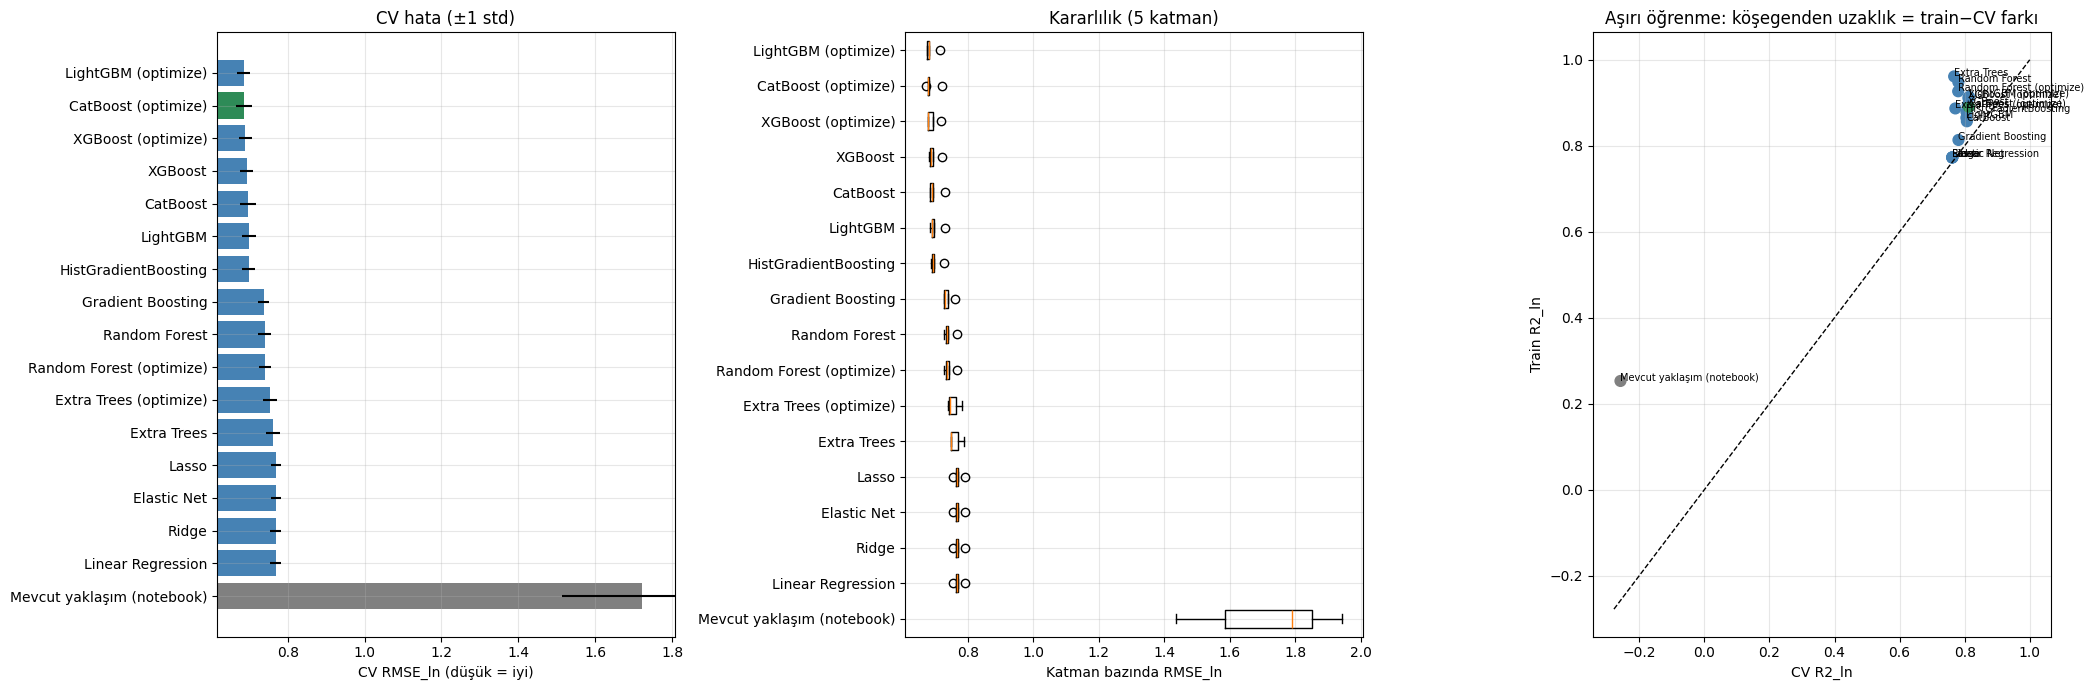

In [26]:
sirali = karsilastirma_df.sort_values("CV RMSE_ln", ascending=False)
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
renk = ["seagreen" if m == FINAL_MODEL_ADI else ("gray" if "Mevcut" in m else "steelblue") for m in sirali.index]
axes[0].barh(sirali.index, sirali["CV RMSE_ln"], xerr=sirali["CV RMSE_ln std"], color=renk)
axes[0].set_xlabel("CV RMSE_ln (düşük = iyi)"); axes[0].set_title("CV hata (±1 std)")
axes[0].set_xlim(sirali["CV RMSE_ln"].min() * 0.9, sirali["CV RMSE_ln"].max() * 1.05)

_kutular = [CV_KAYITLARI[m]["val_RMSE_ln"] for m in sirali.index]
try:
    axes[1].boxplot(_kutular, orientation="horizontal")  # matplotlib >= 3.10
except TypeError:
    axes[1].boxplot(_kutular, vert=False)
axes[1].set_yticks(range(1, len(sirali) + 1), sirali.index)
axes[1].set_xlabel("Katman bazında RMSE_ln"); axes[1].set_title("Kararlılık (5 katman)")

axes[2].scatter(sirali["CV R2_ln"], sirali["Train R2_ln"], c=renk, s=60)
for m in sirali.index:
    axes[2].annotate(m, (sirali.loc[m, "CV R2_ln"], sirali.loc[m, "Train R2_ln"]), fontsize=7)
lim = [min(sirali["CV R2_ln"].min(), sirali["Train R2_ln"].min()) - 0.02, 1.0]
axes[2].plot(lim, lim, "k--", lw=1); axes[2].set_xlabel("CV R2_ln"); axes[2].set_ylabel("Train R2_ln")
axes[2].set_title("Aşırı öğrenme: köşegenden uzaklık = train−CV farkı")
plt.tight_layout(); plt.show()

## 13. Final Model

Seçilen model, seçilen özellik seti ve hedef dönüşümüyle **tüm eğitim seti** üzerinde yeniden eğitilir.

In [27]:
def model_kurucu(ad):
    if ad in OPT_MODEL_KURUCULAR:
        return OPT_MODEL_KURUCULAR[ad], SET_AGAC
    spec = MODEL_KATALOGU[ad]
    set_adi = model_seti(spec["olcekle"])
    return (lambda: pipeline_kur(spec["kur"](), set_adi, EN_IYI_DONUSUM, spec["olcekle"])), set_adi


_kurucu, FINAL_SET = model_kurucu(FINAL_MODEL_ADI)


final_model = _kurucu()
t0 = time.time()
final_model.fit(X_train, Y_train)
print(f"Final model: {FINAL_MODEL_ADI}  |  özellik seti: {FINAL_SET}  |  hedef dönüşümü: {EN_IYI_DONUSUM}  "
      f"|  eğitim süresi: {time.time() - t0:.1f} sn")
print("Pipeline:", final_model.regressor_)
final_train_metrik = metrikler(Y_train, final_model.predict(X_train))
pd.Series(final_train_metrik, name="Train").round(4)

Final model: CatBoost (optimize)  |  özellik seti: fiziksel+koordinat  |  hedef dönüşümü: ln  |  eğitim süresi: 37.7 sn
Pipeline: Pipeline(steps=[('ozellik',
                 DepremOzellikleri(ozellik_seti='fiziksel+koordinat')),
                ('eksik', SimpleImputer(add_indicator=True, strategy='median')),
                ('model',
                 CatBoostRegressor(allow_writing_files=False, bagging_temperature=0.15599452033620265, depth=8, iterations=700, l2_leaf_reg=7.6611007077713635, learning_rate=0.10790061933340454, loss_function='MultiRMSE', random_seed=42, random_strength=0.20513382630874505, verbose=0))])


,Train
R2_ln,0.8862
RMSE_ln,0.5455
MAE_ln,0.4172
MedAE_ln,0.3362
EV_ln,0.8862
R2_orij,0.7345
MAPE_orij_%,45.9156


## 14. Test Evaluation

Test seti burada **ilk ve tek kez** kullanılır. Mevcut yaklaşım da aynı eğitim setiyle eğitilip aynı test
setinde değerlendirilir. Mevcut yaklaşım Vs30 bilinmeyen kayıtları tahmin edemediği için adil karşılaştırma
**ortak alt küme (Vs30 bilinen test kayıtları)** üzerinde yapılır; final model ayrıca tüm test setinde raporlanır.
Farkın güvenilirliği, test olayları üzerinde **olay bazlı bootstrap** ile %95 güven aralığı hesaplanarak sınanır.

In [28]:
P_test_final = final_model.predict(X_test)

mevcut_model = mevcut_model_kur()
mevcut_model.fit(X_train[VS30_BILINEN_TRAIN], Y_train[VS30_BILINEN_TRAIN])
ortak = X_test["Vs30"].notna().values
P_test_mevcut = mevcut_model.predict(X_test[ortak])

test_tablo = pd.DataFrame({
    "Mevcut yaklaşım (ortak alt küme)": metrikler(Y_test[ortak], P_test_mevcut),
    f"{FINAL_MODEL_ADI} (ortak alt küme)": metrikler(Y_test[ortak], P_test_final[ortak]),
    f"{FINAL_MODEL_ADI} (tüm test)": metrikler(Y_test, P_test_final),
})


def bootstrap_rmse_farki(Y, P_a, P_b, g, n=N_BOOTSTRAP):
    """RMSE_ln(a) - RMSE_ln(b); olaylar yerine koyarak yeniden örneklenir."""
    rng = np.random.default_rng(RANDOM_STATE)
    olaylar = np.unique(g)
    indeks = {o: np.where(g == o)[0] for o in olaylar}
    farklar = []
    for _ in range(n):
        ii = np.concatenate([indeks[o] for o in rng.choice(olaylar, len(olaylar), replace=True)])
        farklar.append(rmse_ln(Y[ii], P_a[ii]) - rmse_ln(Y[ii], P_b[ii]))
    return np.percentile(farklar, [2.5, 50, 97.5])


BOOT_CI = bootstrap_rmse_farki(Y_test[ortak], P_test_mevcut, P_test_final[ortak], g_test[ortak])
print(f"Test: {len(X_test)} kayıt / {len(np.unique(g_test))} olay  |  ortak alt küme: {ortak.sum()} kayıt")
print(f"RMSE_ln(mevcut) − RMSE_ln(final) = {BOOT_CI[1]:.4f}  (%95 GA: {BOOT_CI[0]:.4f} … {BOOT_CI[2]:.4f})")
print("GA tamamen 0'ın üzerindeyse iyileşme istatistiksel olarak güvenilirdir.")
test_tablo.round(4)

Test: 6509 kayıt / 853 olay  |  ortak alt küme: 4712 kayıt
RMSE_ln(mevcut) − RMSE_ln(final) = 0.8278  (%95 GA: 0.7234 … 0.9487)
GA tamamen 0'ın üzerindeyse iyileşme istatistiksel olarak güvenilirdir.


,Mevcut yaklaşım (ortak alt küme),CatBoost (optimize) (ortak alt küme),CatBoost (optimize) (tüm test)
R2_ln,0.1505,0.8311,0.8021
RMSE_ln,1.4792,0.6510,0.6941
MAE_ln,0.8062,0.4990,0.5306
MedAE_ln,0.5624,0.4020,0.4279
EV_ln,0.1585,0.8314,0.8024
R2_orij,0.5810,0.6196,0.6045
MAPE_orij_%,112.7029,55.1350,59.9480


In [29]:
print(f"Final model — hedef bazında TEST metrikleri (tüm test seti, orijinal birimler dahil):")
display(hedef_bazli_metrikler(Y_test, P_test_final).round(4))
print("Mevcut yaklaşım — hedef bazında TEST metrikleri (ortak alt küme):")
display(hedef_bazli_metrikler(Y_test[ortak], P_test_mevcut).round(4))
print("Not: MAPE, hedefler sıfıra yakın çok küçük değerler aldığında şişer; oransal hata için RMSE_ln (σ) daha güvenilirdir.")

Final model — hedef bazında TEST metrikleri (tüm test seti, orijinal birimler dahil):


,R2_ln,RMSE_ln (σ),MAE_ln,R2_orij,RMSE_orij,MAE_orij,MedAE_orij,MAPE_orij_%
Hedef,,,,,,,,
PGA (g),0.7397,0.7071,0.5449,0.5776,0.0060,0.0012,0.0002,61.6345
PGV (cm/s),0.8054,0.6688,0.5162,0.6394,0.3817,0.0695,0.0091,57.4745
PGD (cm),0.8610,0.7062,0.5306,0.5964,0.2020,0.0214,0.0009,60.7352


Mevcut yaklaşım — hedef bazında TEST metrikleri (ortak alt küme):


,R2_ln,RMSE_ln (σ),MAE_ln,R2_orij,RMSE_orij,MAE_orij,MedAE_orij,MAPE_orij_%
Hedef,,,,,,,,
PGA (g),-0.0796,1.4625,0.8179,0.6233,0.0063,0.0016,0.0004,110.7861
PGV (cm/s),0.5862,0.9882,0.6153,0.6042,0.4503,0.0874,0.0130,82.5076
PGD (cm),-0.0551,1.9870,0.9855,0.5219,0.2555,0.0305,0.0018,138.3505


Not: MAPE, hedefler sıfıra yakın çok küçük değerler aldığında şişer; oransal hata için RMSE_ln (σ) daha güvenilirdir.


### 14.1 Aşırı öğrenme kontrolü (Train / CV / Test)

In [30]:
final_cv = karsilastirma_df.loc[FINAL_MODEL_ADI]
test_m = metrikler(Y_test, P_test_final)
asiri = pd.DataFrame({
    "Train": [final_train_metrik["R2_ln"], final_train_metrik["RMSE_ln"], final_train_metrik["MAE_ln"]],
    "CV (ort ± std)": [f"{final_cv['CV R2_ln']:.4f} ± {final_cv['CV R2_ln std']:.4f}",
                       f"{final_cv['CV RMSE_ln']:.4f} ± {final_cv['CV RMSE_ln std']:.4f}",
                       f"{final_cv['CV MAE_ln']:.4f}"],
    "Test": [test_m["R2_ln"], test_m["RMSE_ln"], test_m["MAE_ln"]],
}, index=["R2_ln", "RMSE_ln", "MAE_ln"])
fark_train_cv = final_train_metrik["R2_ln"] - final_cv["CV R2_ln"]
fark_cv_test = final_cv["CV R2_ln"] - test_m["R2_ln"]
ASIRI_OGRENME = "Var" if fark_train_cv > 0.10 else "Yok"
print(f"Train−CV R2 farkı: {fark_train_cv:.4f}  ({asiri_ogrenme_durumu(fark_train_cv)})")
print(f"CV−Test R2 farkı: {fark_cv_test:.4f}  (küçükse CV tahmini test performansını doğru öngörmüş demektir)")
asiri

Train−CV R2 farkı: 0.0733  (hafif)
CV−Test R2 farkı: 0.0108  (küçükse CV tahmini test performansını doğru öngörmüş demektir)


,Train,CV (ort ± std),Test
R2_ln,0.886203,0.8129 ± 0.0362,0.802056
RMSE_ln,0.545549,0.6861 ± 0.0204,0.694059
MAE_ln,0.417250,0.5240,0.530583


## 15. Feature Importance

- **Model içi önem** (ağaç modelleri): türetilmiş özellikler üzerinde.
- **Permütasyon önemi**: *ham girdiler* (`Mw`, `Rhyp`, `Depth`, `Vs30`) tek tek karıştırılır ve
  türetilmiş tüm özellikler buna göre yeniden hesaplanır; böylece `Mw`'nin toplam etkisi (Mw, Mw², Mw·lnR
  üzerinden) tek bir değerde görülür. Test setinde hesaplanır; hiçbir modelleme kararında **kullanılmaz**.

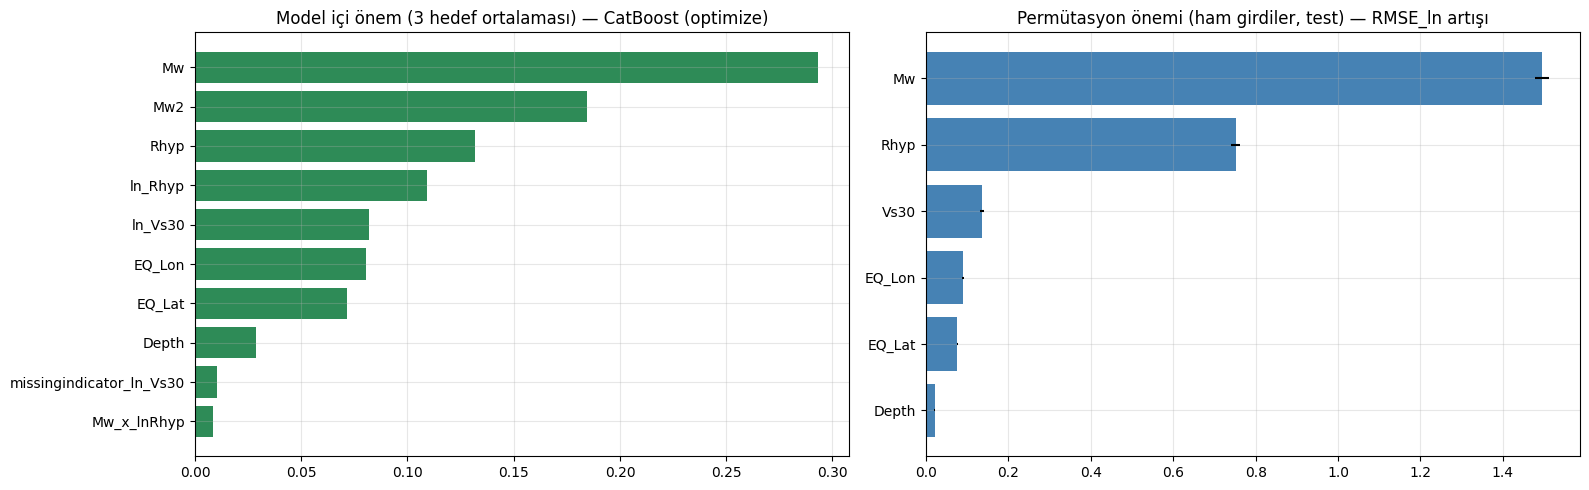

,RMSE_ln artışı,std
Mw,1.4956,0.0163
Rhyp,0.7514,0.0112
Vs30,0.1356,0.0040
EQ_Lon,0.0892,0.0029
EQ_Lat,0.0762,0.0018
Depth,0.0207,0.0016


In [31]:
on_isleme = final_model.regressor_[:-1]
ic_model = final_model.regressor_.named_steps["model"]
ozellik_adlari = list(on_isleme.transform(X_train.head()).columns)


def model_ici_onem(model):
    tahminciler = model.estimators_ if isinstance(model, MultiOutputRegressor) else [model]
    onemler = []
    for est in tahminciler:
        if HAS_LGBM and isinstance(est, LGBMRegressor):
            v = est.booster_.feature_importance(importance_type="gain").astype(float)
        elif HAS_CAT and isinstance(est, CatBoostRegressor):
            v = np.asarray(est.get_feature_importance(), dtype=float)
        elif hasattr(est, "feature_importances_"):
            v = np.asarray(est.feature_importances_, dtype=float)
        elif hasattr(est, "coef_"):
            v = np.abs(np.atleast_2d(est.coef_)).mean(axis=0)
        else:
            return None
        onemler.append(v / v.sum())
    return pd.Series(np.mean(onemler, axis=0), index=ozellik_adlari).sort_values()


ic_onem = model_ici_onem(ic_model)
perm = permutation_importance(final_model, X_test, Y_test,
                              scoring=lambda est, X, Y: -rmse_ln(Y, est.predict(X)),
                              n_repeats=N_PERM_REPEATS, random_state=RANDOM_STATE)
perm_onem = pd.DataFrame({"RMSE_ln artışı": perm.importances_mean, "std": perm.importances_std},
                         index=X_test.columns).sort_values("RMSE_ln artışı")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
if ic_onem is not None:
    axes[0].barh(ic_onem.index, ic_onem.values, color="seagreen")
    axes[0].set_title(f"Model içi önem (3 hedef ortalaması) — {FINAL_MODEL_ADI}")
axes[1].barh(perm_onem.index, perm_onem["RMSE_ln artışı"], xerr=perm_onem["std"], color="steelblue")
axes[1].set_title("Permütasyon önemi (ham girdiler, test) — RMSE_ln artışı")
plt.tight_layout(); plt.show()
perm_onem.sort_values("RMSE_ln artışı", ascending=False).round(4)

## 16. SHAP Analysis

SHAP değerleri **ln(hedef)** ölçeğindedir: bir özelliğin +0.69 katkısı tahmini yaklaşık 2 katına çıkarır.

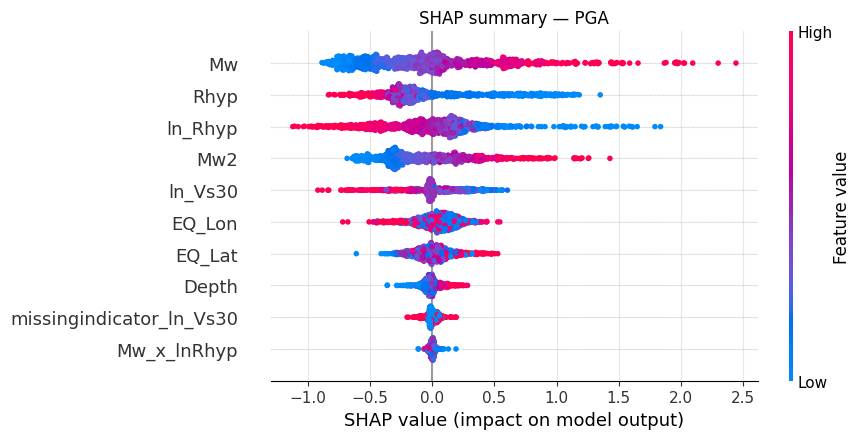

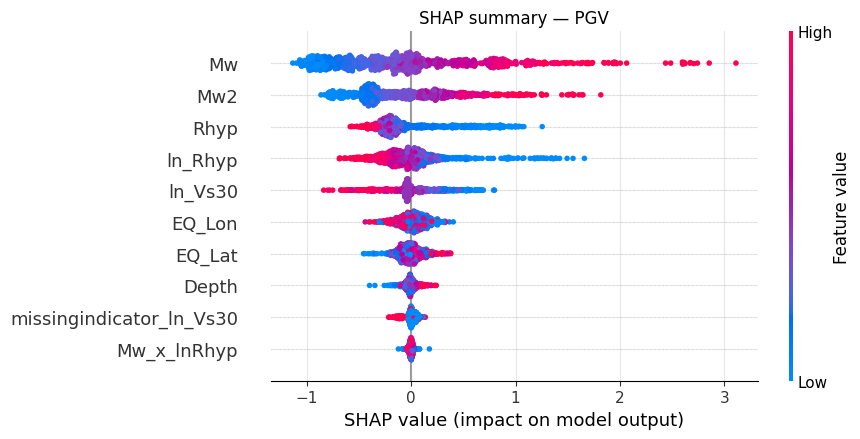

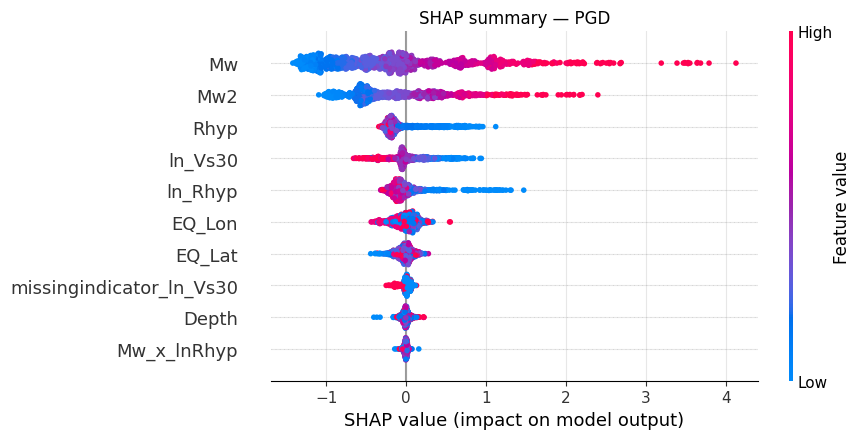

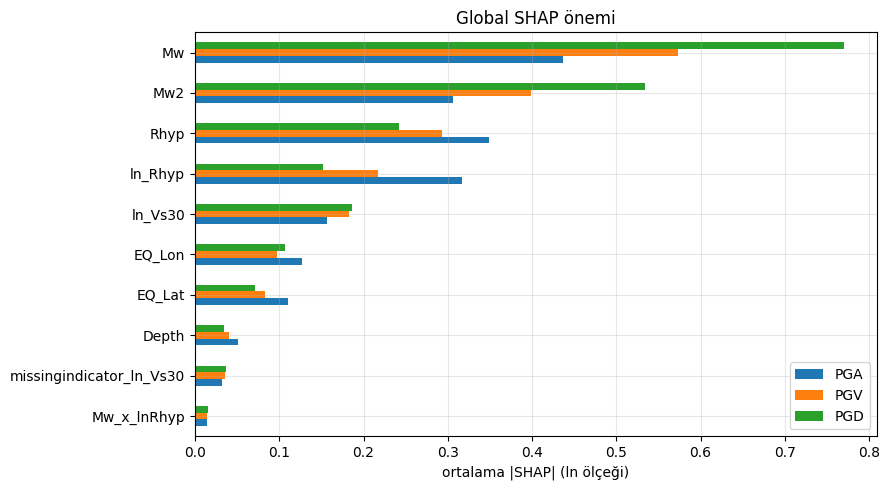

,PGA,PGV,PGD,ortalama
Mw,0.4368,0.5734,0.7703,0.5935
Mw2,0.3062,0.3986,0.5344,0.4131
Rhyp,0.3487,0.2928,0.2420,0.2945
ln_Rhyp,0.3174,0.2173,0.1514,0.2287
ln_Vs30,0.1570,0.1828,0.1860,0.1752
EQ_Lon,0.1272,0.0973,0.1071,0.1105
EQ_Lat,0.1101,0.0833,0.0710,0.0881
Depth,0.0505,0.0405,0.0347,0.0419
missingindicator_ln_Vs30,0.0316,0.0353,0.0362,0.0344
Mw_x_lnRhyp,0.0147,0.0139,0.0155,0.0147


In [32]:
SHAP_LISTESI = None
if HAS_SHAP:
    rng = np.random.default_rng(RANDOM_STATE)
    orn = rng.choice(len(X_test), size=min(SHAP_ORNEK, len(X_test)), replace=False)
    X_shap = on_isleme.transform(X_test.iloc[orn])

    def shap_hesapla(model, Xs):
        if HAS_CAT and isinstance(model, CatBoostRegressor):
            # Çok çıktılı (MultiRMSE) CatBoost için shap.TreeExplainer kararsız; CatBoost'un kendi SHAP'i kullanılır.
            from catboost import Pool
            sv = np.asarray(model.get_feature_importance(Pool(Xs), type="ShapValues"))
            if sv.ndim == 3:  # (n, çıktı, özellik+1); son sütun beklenen değer
                return [sv[:, i, :-1] for i in range(sv.shape[1])]
            return [sv[:, :-1]]
        if isinstance(model, MultiOutputRegressor):
            return [np.asarray(shap.TreeExplainer(e).shap_values(Xs)) for e in model.estimators_]
        try:
            sv = shap.TreeExplainer(model).shap_values(Xs)
        except Exception as e:
            print("TreeExplainer uygun değil, model-bağımsız Explainer kullanılıyor:", type(e).__name__)
            arka = Xs.sample(min(100, len(Xs)), random_state=RANDOM_STATE)
            return [shap.Explainer(lambda A, i=i: model.predict(pd.DataFrame(A, columns=Xs.columns))[:, i],
                                   arka)(Xs).values for i in range(len(HEDEFLER))]
        if isinstance(sv, list):
            return [np.asarray(s) for s in sv]
        sv = np.asarray(sv)
        return [sv[:, :, i] for i in range(sv.shape[2])] if sv.ndim == 3 else [sv]

    SHAP_LISTESI = shap_hesapla(ic_model, X_shap)
    shap_global = pd.DataFrame({k: np.abs(s).mean(axis=0) for k, s in zip(HEDEF_KISA, SHAP_LISTESI)},
                               index=X_shap.columns)
    shap_global["ortalama"] = shap_global.mean(axis=1)
    shap_global = shap_global.sort_values("ortalama", ascending=False)

    for k, s in zip(HEDEF_KISA, SHAP_LISTESI):
        shap.summary_plot(s, X_shap, show=False, plot_size=(9, 4.5))
        plt.title(f"SHAP summary — {k}"); plt.tight_layout(); plt.show()

    ax = shap_global[HEDEF_KISA].iloc[::-1].plot.barh(figsize=(9, 5))
    ax.set_xlabel("ortalama |SHAP| (ln ölçeği)"); ax.set_title("Global SHAP önemi")
    plt.tight_layout(); plt.show()
    display(shap_global.round(4))
else:
    print("SHAP kurulu değil; bu bölüm atlandı.")

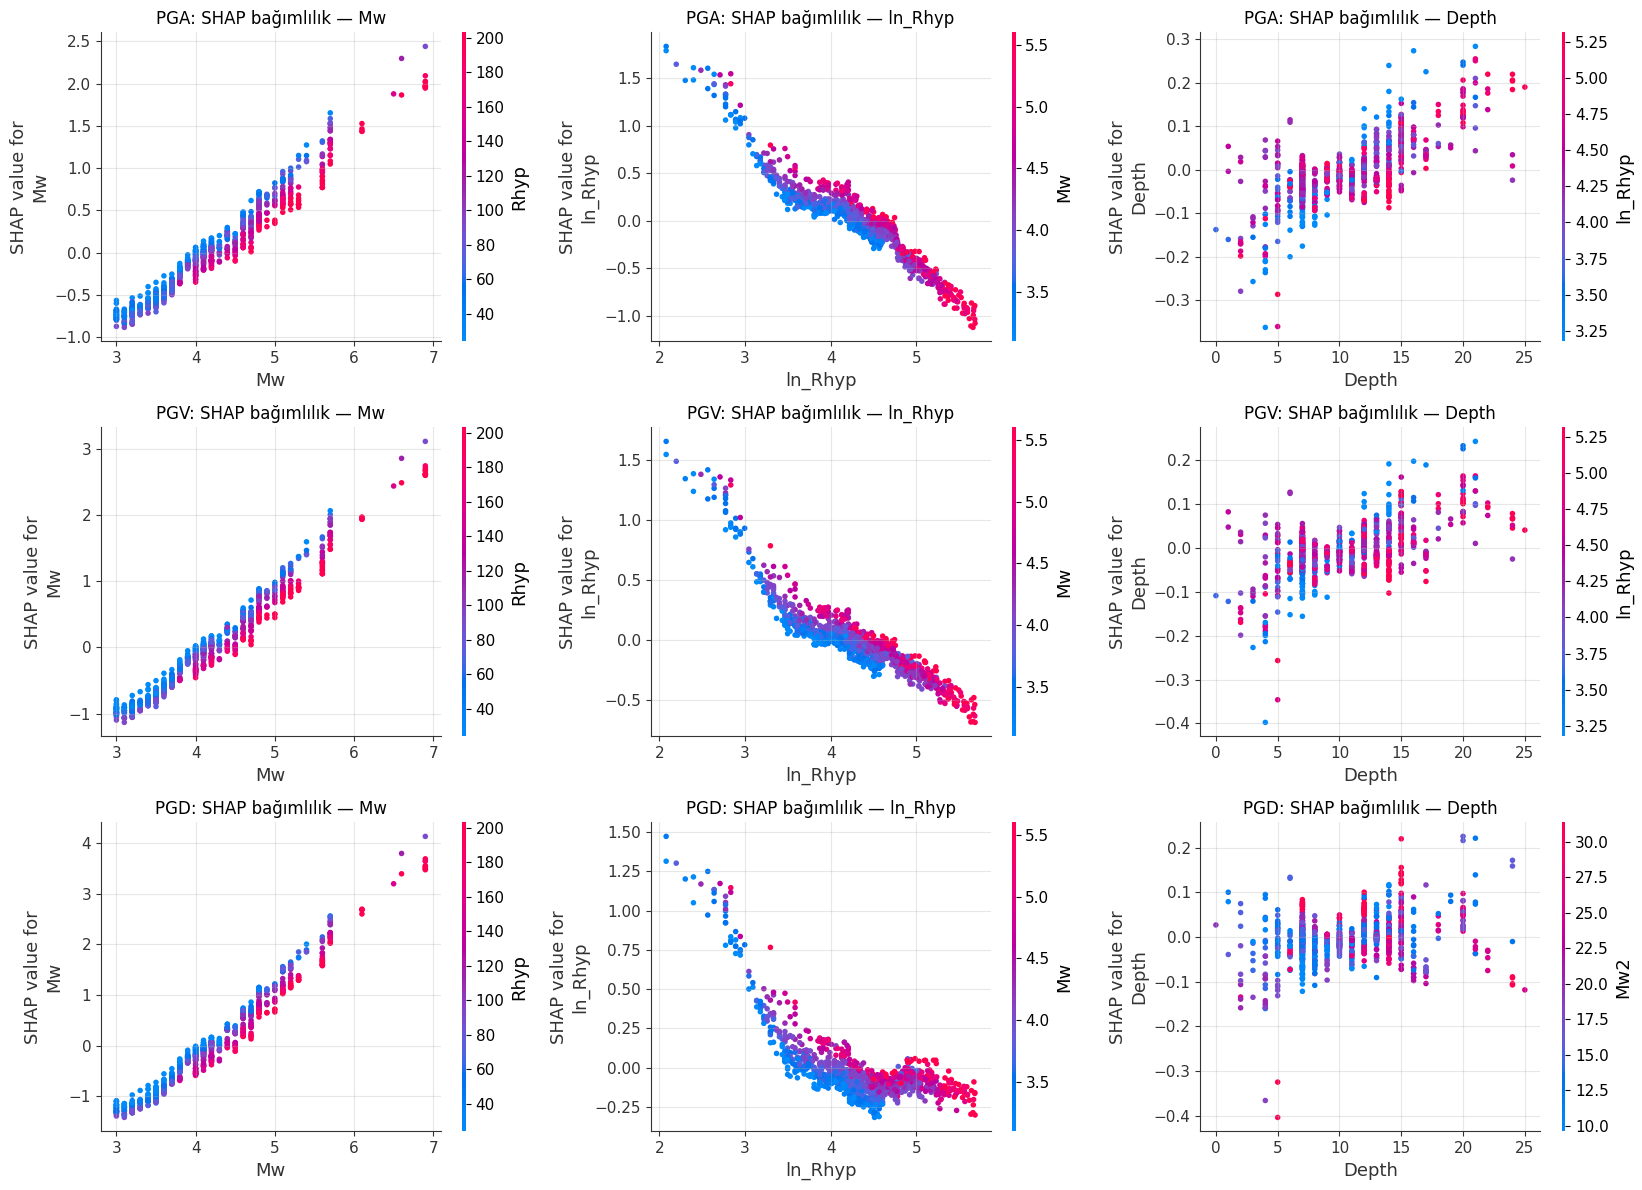

In [33]:
if SHAP_LISTESI is not None:
    bagimlilik = [c for c in ["Mw", "ln_Rhyp", "Log_Rhyp", "Rhyp", "Depth"] if c in X_shap.columns]
    bagimlilik = [c for c in bagimlilik if not (c == "Rhyp" and ("ln_Rhyp" in bagimlilik or "Log_Rhyp" in bagimlilik))]
    fig, axes = plt.subplots(len(HEDEF_KISA), len(bagimlilik), figsize=(5.5 * len(bagimlilik), 4 * len(HEDEF_KISA)))
    axes = np.atleast_2d(axes)
    for i, (k, s) in enumerate(zip(HEDEF_KISA, SHAP_LISTESI)):
        for j, c in enumerate(bagimlilik):
            shap.dependence_plot(c, s, X_shap, ax=axes[i, j], show=False)
            axes[i, j].set_title(f"{k}: SHAP bağımlılık — {c}")
    plt.tight_layout(); plt.show()

## 17. Residual Analysis

Kalıntı = `ln(gözlenen) − ln(tahmin)` (test seti). Kırmızı çizgi, değişkenin 10 eşit-sayılı dilimindeki
ortalama kalıntıdır; sıfırdan sistematik sapma, modelin o bölgede yanlı olduğunu gösterir. Ayrıca kalıntılar
yer hareketi literatüründeki gibi **olay-arası (τ)** ve **olay-içi (φ)** bileşenlerine ayrılır.

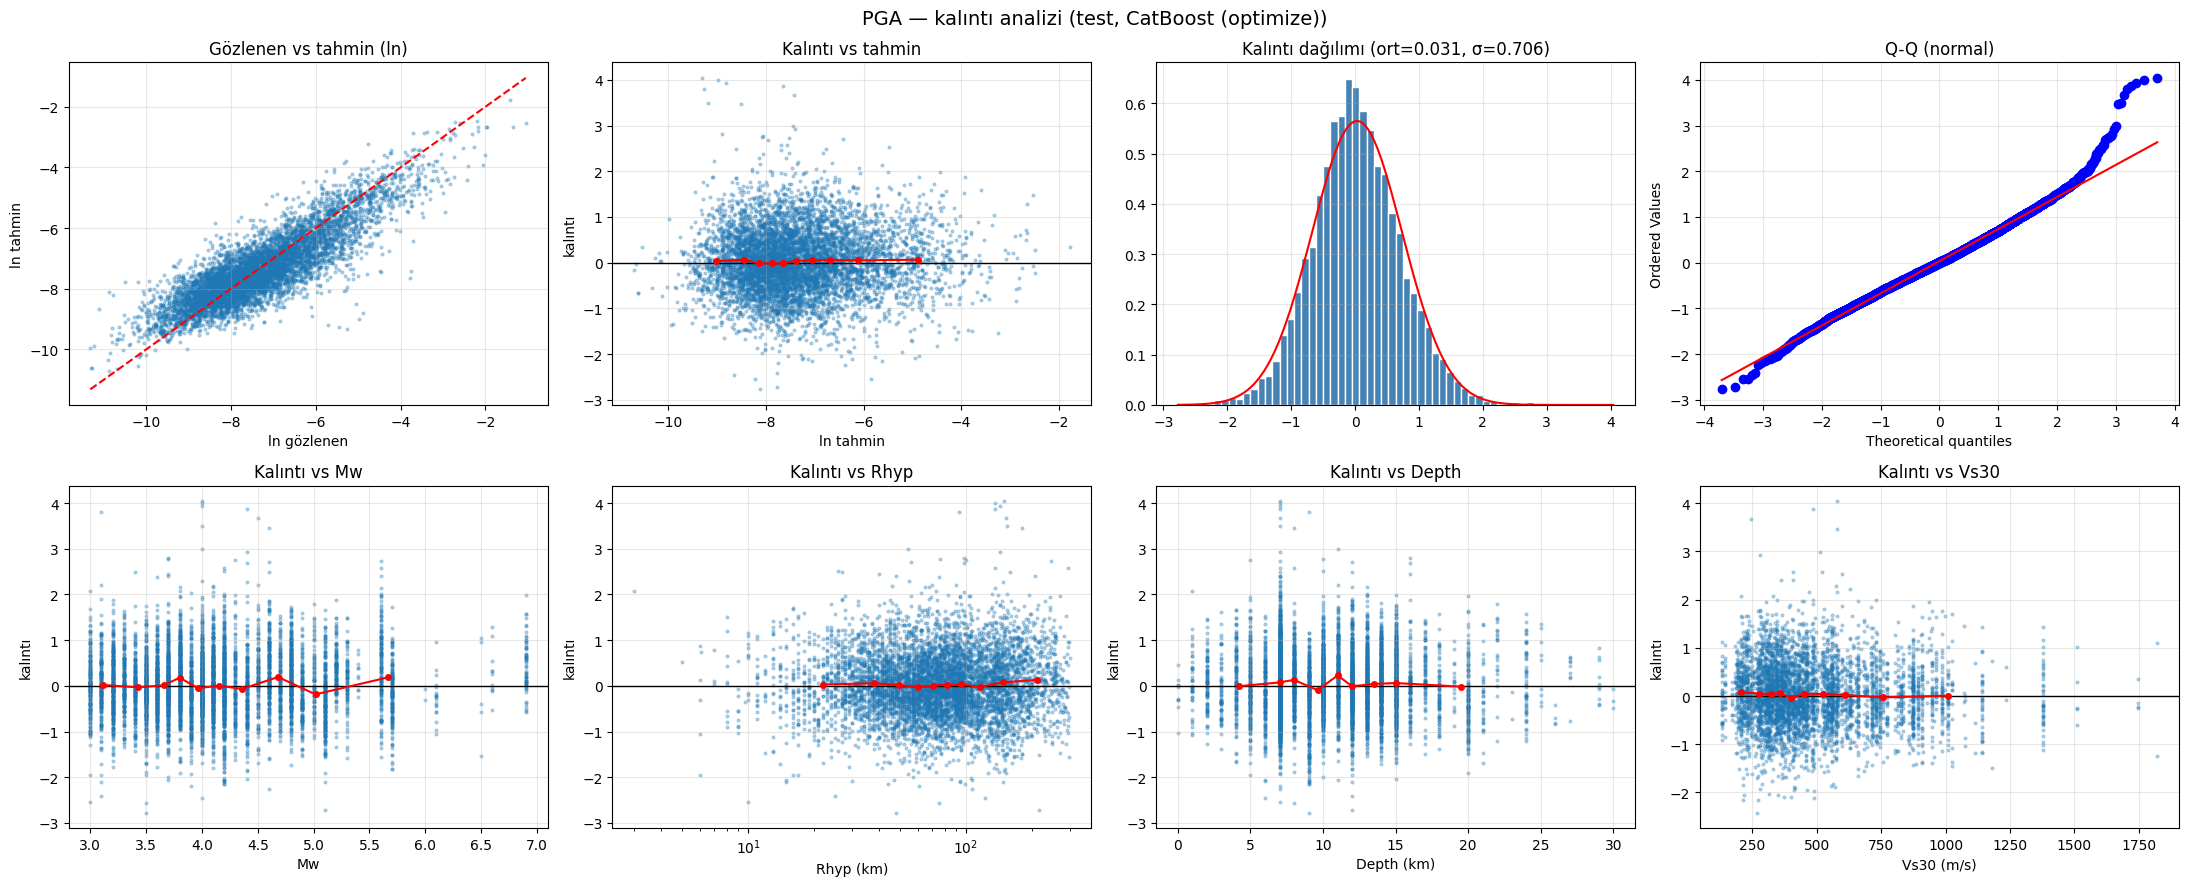

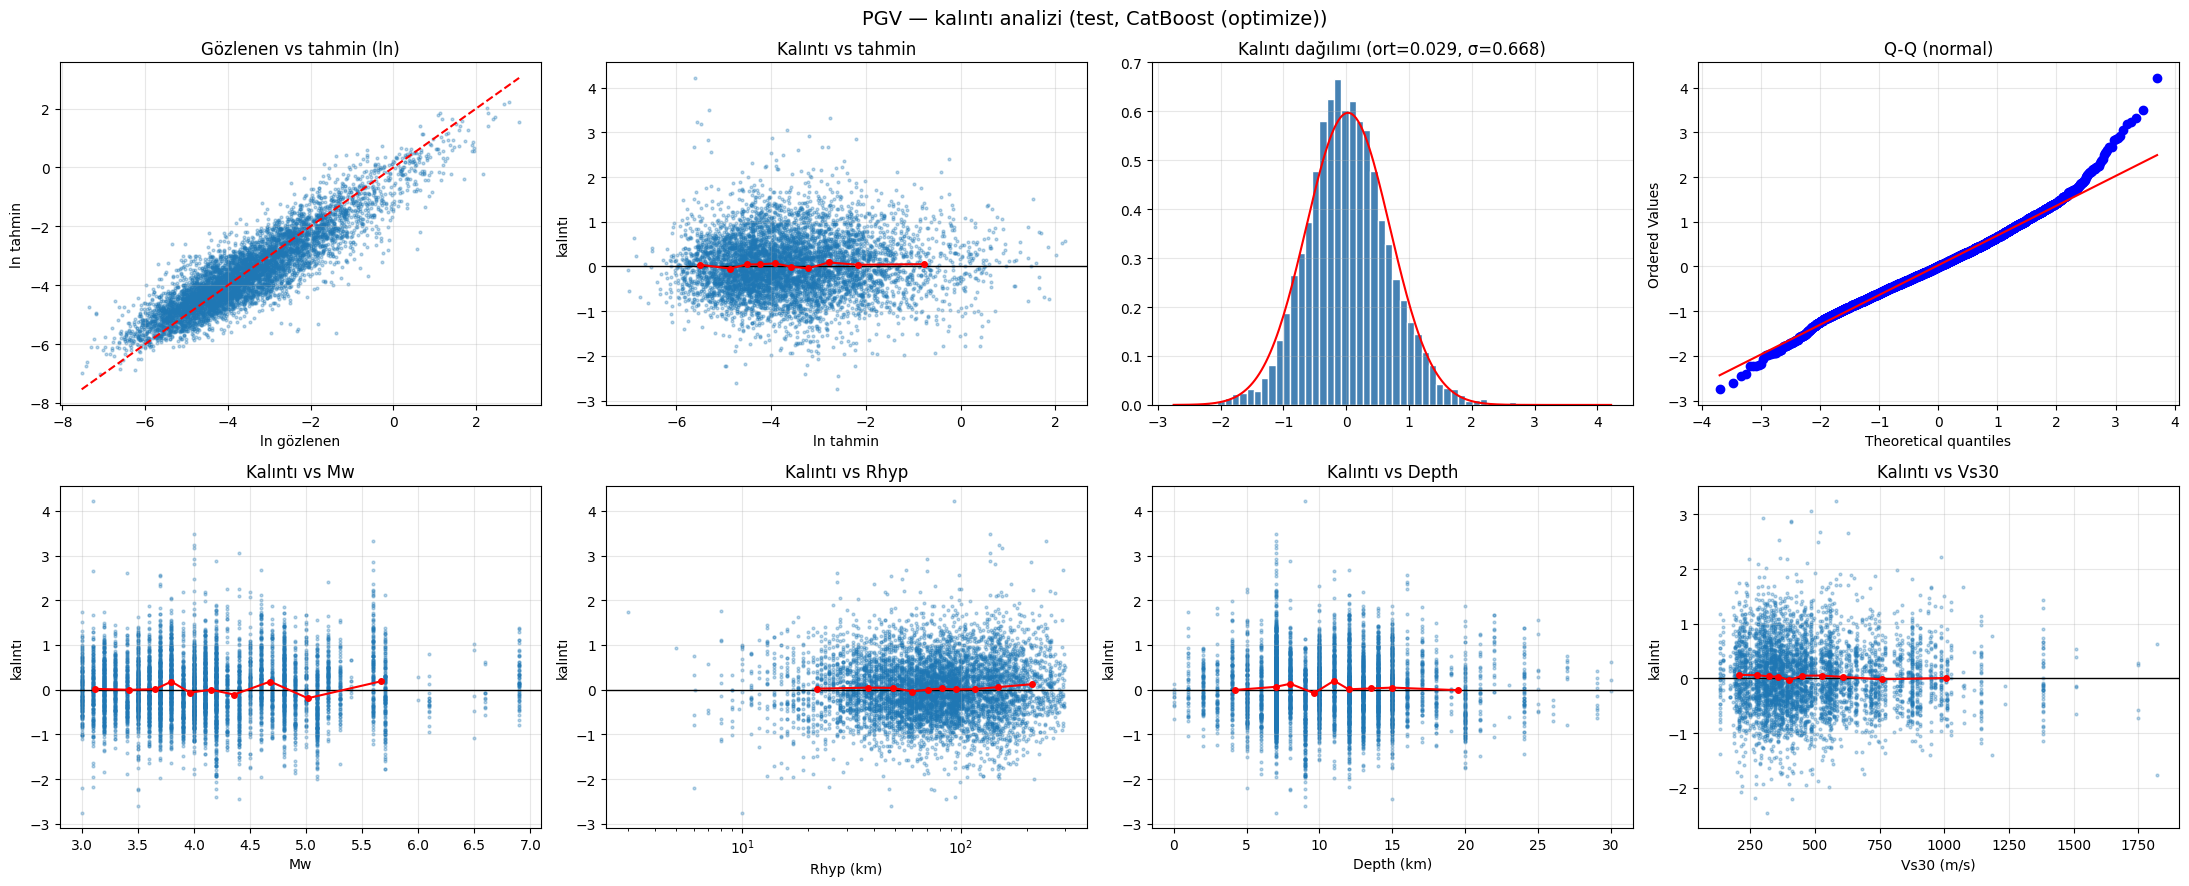

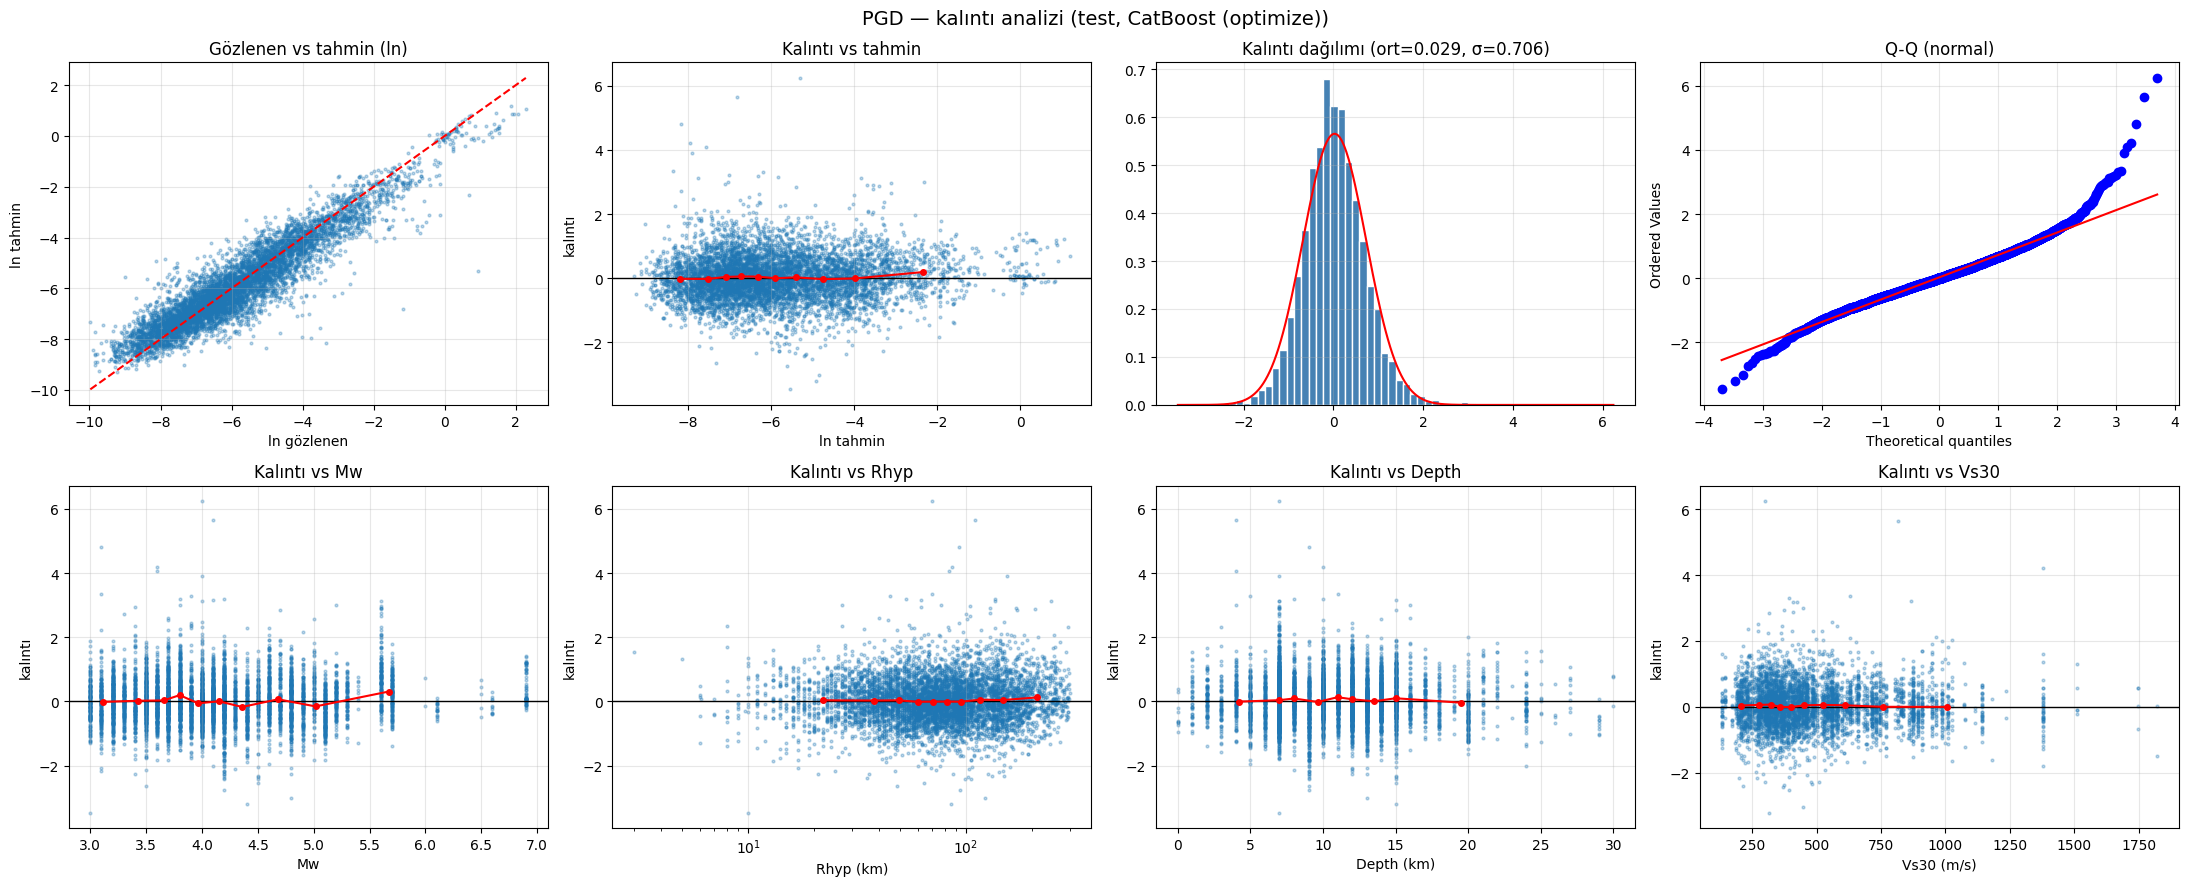

In [34]:
L_true, L_pred = np.log(Y_test), np.log(np.clip(P_test_final, EPS, None))
KALINTI = L_true - L_pred
Xr = X_test.assign(ln_Rhyp=np.log(X_test["Rhyp"].clip(lower=1)))


def dilim_ortalamasi(x, r, n=10):
    d = pd.DataFrame({"x": x, "r": r}).dropna()
    d["bin"] = pd.qcut(d["x"], n, duplicates="drop")
    g = d.groupby("bin", observed=True).agg(x=("x", "mean"), r=("r", "mean"))
    return g["x"].values, g["r"].values


for i, k in enumerate(HEDEF_KISA):
    r = KALINTI[:, i]
    fig, axes = plt.subplots(2, 4, figsize=(22, 9))
    ax = axes[0, 0]; ax.scatter(L_true[:, i], L_pred[:, i], s=4, alpha=0.3)
    lim = [min(L_true[:, i].min(), L_pred[:, i].min()), max(L_true[:, i].max(), L_pred[:, i].max())]
    ax.plot(lim, lim, "r--"); ax.set_xlabel("ln gözlenen"); ax.set_ylabel("ln tahmin"); ax.set_title("Gözlenen vs tahmin (ln)")
    ax = axes[0, 1]; ax.scatter(L_pred[:, i], r, s=4, alpha=0.3); ax.axhline(0, color="k", lw=1)
    xb, rb = dilim_ortalamasi(L_pred[:, i], r); ax.plot(xb, rb, "r-o", ms=4)
    ax.set_xlabel("ln tahmin"); ax.set_ylabel("kalıntı"); ax.set_title("Kalıntı vs tahmin")
    ax = axes[0, 2]; ax.hist(r, bins=60, density=True, color="steelblue", edgecolor="white")
    xs = np.linspace(r.min(), r.max(), 200); ax.plot(xs, stats.norm.pdf(xs, r.mean(), r.std()), "r-")
    ax.set_title(f"Kalıntı dağılımı (ort={r.mean():.3f}, σ={r.std():.3f})")
    stats.probplot(r, dist="norm", plot=axes[0, 3]); axes[0, 3].set_title("Q-Q (normal)")
    for ax, (c, xlab) in zip(axes[1, :], [("Mw", "Mw"), ("Rhyp", "Rhyp (km)"), ("Depth", "Depth (km)"), ("Vs30", "Vs30 (m/s)")]):
        ax.scatter(Xr[c], r, s=4, alpha=0.3); ax.axhline(0, color="k", lw=1)
        xb, rb = dilim_ortalamasi(Xr[c].values, r); ax.plot(xb, rb, "r-o", ms=4)
        if c == "Rhyp":
            ax.set_xscale("log")
        ax.set_xlabel(xlab); ax.set_ylabel("kalıntı"); ax.set_title(f"Kalıntı vs {c}")
    fig.suptitle(f"{k} — kalıntı analizi (test, {FINAL_MODEL_ADI})", fontsize=14)
    plt.tight_layout(); plt.show()

In [35]:
# Sistematik örüntü testi: Spearman korelasyonu ve dilim ortalamalarının en büyük mutlak sapması.
# Ölçüt (önceden belirlenmiş): |rho| > 0.10 ve p < 0.001  veya  max|dilim ortalaması| > 0.25 ln birimi (~%28)
oruntu = []
for i, k in enumerate(HEDEF_KISA):
    for c in ["Mw", "ln_Rhyp", "Depth", "Vs30"]:
        x = Xr[c].values
        m = ~np.isnan(x)
        rho, p = stats.spearmanr(x[m], KALINTI[m, i])
        _, rb = dilim_ortalamasi(x, KALINTI[:, i])
        sistematik = (abs(rho) > 0.10 and p < 1e-3) or np.max(np.abs(rb)) > 0.25
        oruntu.append({"Hedef": k, "Değişken": c, "Spearman rho": rho, "p": p,
                       "max |dilim ort.|": np.max(np.abs(rb)), "Sistematik?": "EVET" if sistematik else "hayır"})
oruntu_df = pd.DataFrame(oruntu)
display(oruntu_df.round(4))

# Olay-arası / olay-içi ayrışımı (en az 3 kaydı olan test olayları)
bilesen = []
for i, k in enumerate(HEDEF_KISA):
    d = pd.DataFrame({"g": g_test, "r": KALINTI[:, i]})
    d = d[d.groupby("g")["r"].transform("size") >= 3]
    olay_terimi = d.groupby("g")["r"].transform("mean")
    bilesen.append({"Hedef": k, "toplam σ": KALINTI[:, i].std(), "τ (olay-arası)": d.groupby("g")["r"].mean().std(),
                    "φ (olay-içi)": (d["r"] - olay_terimi).std(), "olay sayısı": d["g"].nunique()})
print("Kalıntı bileşenleri (ln birimi):")
pd.DataFrame(bilesen).set_index("Hedef").round(4)

,Hedef,Değişken,Spearman rho,p,max |dilim ort.|,Sistematik?
0,PGA,Mw,0.0361,0.0036,0.1926,hayır
1,PGA,ln_Rhyp,0.0178,0.1514,0.1294,hayır
2,PGA,Depth,-0.0039,0.7540,0.2280,hayır
3,PGA,Vs30,-0.0453,0.0019,0.0819,hayır
4,PGV,Mw,0.0273,0.0274,0.1908,hayır
5,PGV,ln_Rhyp,0.0196,0.1139,0.1233,hayır
6,PGV,Depth,0.0002,0.9876,0.1998,hayır
7,PGV,Vs30,-0.0369,0.0113,0.0653,hayır
8,PGD,Mw,0.0445,0.0003,0.3065,EVET
9,PGD,ln_Rhyp,0.0112,0.3669,0.1251,hayır


Kalıntı bileşenleri (ln birimi):


,toplam σ,τ (olay-arası),φ (olay-içi),olay sayısı
Hedef,,,,
PGA,0.7064,0.4780,0.5548,494
PGV,0.6682,0.4410,0.5195,494
PGD,0.7056,0.4846,0.5345,494


## 18. Actual vs Predicted

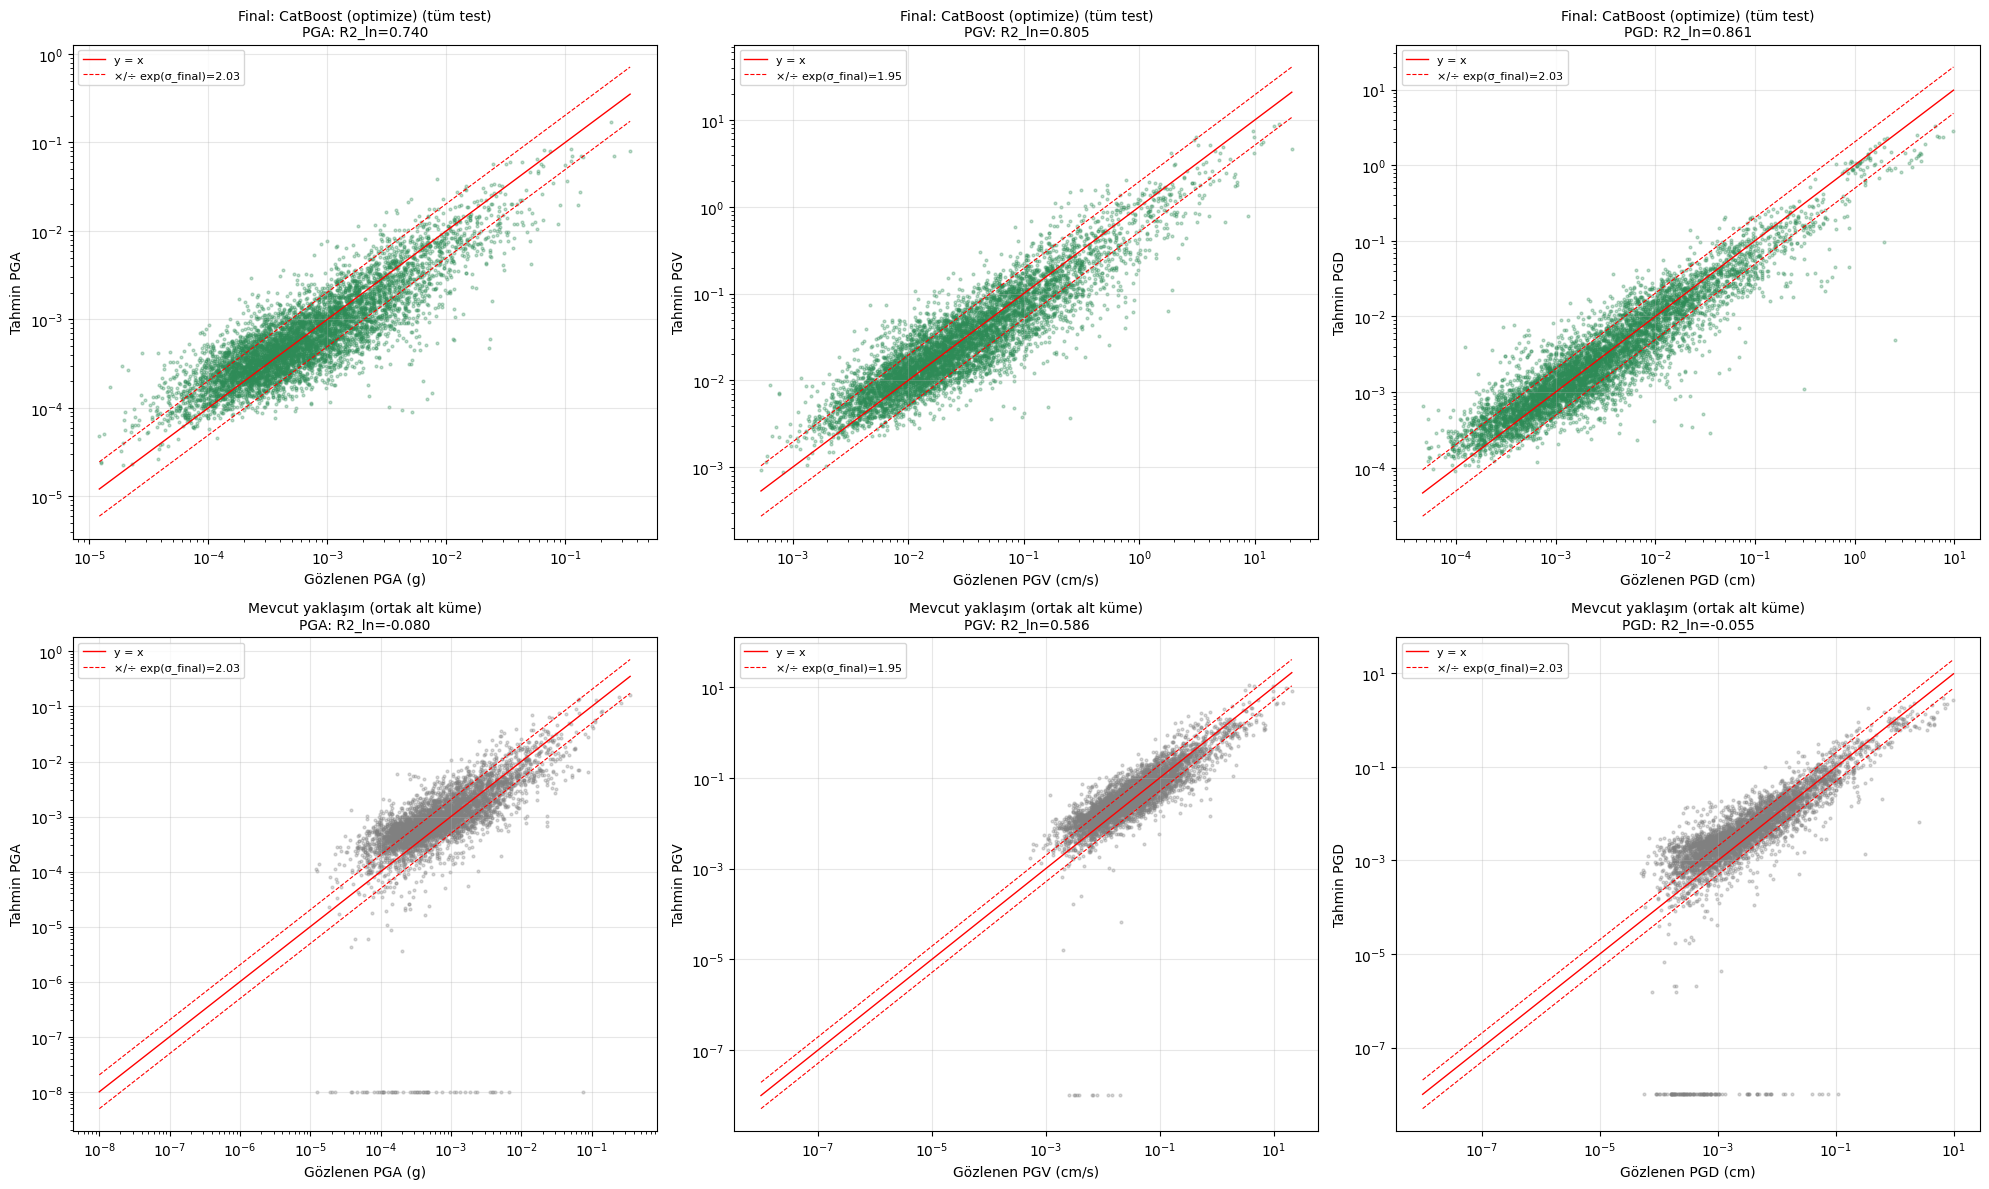

In [36]:
sigma_test = KALINTI.std(axis=0)
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
for i, k in enumerate(HEDEF_KISA):
    for satir, (ad, Yg, Pg) in enumerate([
            (f"Final: {FINAL_MODEL_ADI} (tüm test)", Y_test[:, i], P_test_final[:, i]),
            ("Mevcut yaklaşım (ortak alt küme)", Y_test[ortak, i], P_test_mevcut[:, i])]):
        ax = axes[satir, i]
        Pg = np.clip(Pg, EPS, None)
        ax.scatter(Yg, Pg, s=4, alpha=0.3, color="seagreen" if satir == 0 else "gray")
        lo, hi = min(Yg.min(), Pg.min()), max(Yg.max(), Pg.max())
        xx = np.geomspace(lo, hi, 50)
        ax.plot(xx, xx, "r-", lw=1, label="y = x")
        ax.plot(xx, xx * np.exp(sigma_test[i]), "r--", lw=0.8, label=f"×/÷ exp(σ_final)={np.exp(sigma_test[i]):.2f}")
        ax.plot(xx, xx / np.exp(sigma_test[i]), "r--", lw=0.8)
        ax.set_xscale("log"); ax.set_yscale("log")
        r2l = r2_score(np.log(Yg), np.log(Pg))
        ax.set_xlabel(f"Gözlenen {k} ({HEDEF_BIRIM[k]})"); ax.set_ylabel(f"Tahmin {k}")
        ax.set_title(f"{ad}\n{k}: R2_ln={r2l:.3f}", fontsize=10); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 19. Final Results

In [37]:
mevcut_test = test_tablo.iloc[:, 0]
final_test_ortak = test_tablo.iloc[:, 1]
final_test_tum = test_tablo.iloc[:, 2]

if SHAP_LISTESI is not None:
    en_onemli = shap_global.index[:5].tolist()
    onem_kaynagi = "ortalama |SHAP|, test örneklemi"
elif ic_onem is not None:
    en_onemli = ic_onem.sort_values(ascending=False).index[:5].tolist()
    onem_kaynagi = "model içi önem"
else:
    en_onemli = perm_onem.sort_values("RMSE_ln artışı", ascending=False).index[:5].tolist()
    onem_kaynagi = "permütasyon önemi"

iyilesme_guvenilir = BOOT_CI[0] > 0
kotulesme_guvenilir = BOOT_CI[2] < 0
if iyilesme_guvenilir:
    sonuc = (f"{FINAL_MODEL_ADI}, bağımsız test setinin ortak alt kümesinde mevcut yaklaşıma göre RMSE_ln'i "
             f"{BOOT_CI[1]:.3f} azalttı (%95 GA {BOOT_CI[0]:.3f}…{BOOT_CI[2]:.3f}); iyileşme istatistiksel olarak güvenilir.")
elif kotulesme_guvenilir:
    sonuc = (f"{FINAL_MODEL_ADI}, mevcut yaklaşımdan güvenilir biçimde DAHA KÖTÜ (GA {BOOT_CI[0]:.3f}…{BOOT_CI[2]:.3f}); "
             "mevcut yaklaşım korunmalı.")
else:
    sonuc = (f"{FINAL_MODEL_ADI} ile mevcut yaklaşım arasındaki fark istatistiksel olarak ayırt edilemiyor "
             f"(GA {BOOT_CI[0]:.3f}…{BOOT_CI[2]:.3f} sıfırı içeriyor); güvenilir bir iyileşme iddia edilemez.")

rapor = f"""
===============================
MODEL GELİŞTİRME RAPORU
===============================

Veri:
- Başlangıç kayıt sayısı: {n_baslangic}
- Filtre sonrası kayıt sayısı: {n_filtre}  (train {len(X_train)} / test {len(X_test)}; {df['OLAY_ID'].nunique()} olay)
- Feature sayısı: {len(GIRDI_SUTUNLARI)} ham girdi -> {len(OZELLIK_SETLERI[FINAL_SET])} özellik ('{FINAL_SET}' seti) + Vs30 eksiklik göstergesi

Baseline (mevcut yaklaşım, olay bazlı test, ortak alt küme; ln ölçeği):
- R²:   {mevcut_test['R2_ln']:.4f}   (orijinal ölçek R² = {mevcut_test['R2_orij']:.4f})
- RMSE: {mevcut_test['RMSE_ln']:.4f}
- MAE:  {mevcut_test['MAE_ln']:.4f}
- CV R²: {mevcut_cv['CV R2_ln']:.4f} ± {mevcut_cv['CV R2_ln std']:.4f}

En iyi model (CV'ye göre seçildi, 1-SE kuralı):
- Model: {FINAL_MODEL_ADI}  (hedef dönüşümü: {EN_IYI_DONUSUM})
- CV R²:     {final_cv['CV R2_ln']:.4f} ± {final_cv['CV R2_ln std']:.4f}
- Test R²:   {final_test_tum['R2_ln']:.4f}  (ortak alt kümede {final_test_ortak['R2_ln']:.4f}; orijinal ölçek R² = {final_test_tum['R2_orij']:.4f})
- Test RMSE: {final_test_tum['RMSE_ln']:.4f}  (ortak alt kümede {final_test_ortak['RMSE_ln']:.4f})
- Test MAE:  {final_test_tum['MAE_ln']:.4f}  (ortak alt kümede {final_test_ortak['MAE_ln']:.4f})

Overfitting:
- {ASIRI_OGRENME}  (train−CV R² farkı {fark_train_cv:.3f}; CV−test R² farkı {fark_cv_test:.3f})

En önemli feature'lar ({onem_kaynagi}):
""" + "\n".join(f"{i + 1}. {f}" for i, f in enumerate(en_onemli)) + f"""

Yapılan değişiklikler:
- Hedef dönüşümü log1p -> {EN_IYI_DONUSUM} (CV ile seçildi)
- Rastgele ayrım -> olay bazlı test ayrımı + 5-katlı GroupKFold CV
- -999 kodlu Depth/Rhyp kayıtları açık kuralla çıkarıldı; Vs30=-1 kayıtları silinmek yerine Pipeline içinde dolduruldu
- Spektral ivme sütunları (hedef sızıntısı) açıkça dışlandı
- Özellik seti ablation ile model ailesine göre seçildi: ağaç='{SET_AGAC}', lineer='{SET_LINEER}'
- {len(MODEL_KATALOGU)} model CV ile karşılaştırıldı; {len(optuna_sonuclari)} model Optuna ile yalnızca CV üzerinde optimize edildi
- Test seti yalnızca final değerlendirmede bir kez kullanıldı

Sonuç:
- {sonuc}
"""
print(rapor)
with open(os.path.join(CIKTI_KLASORU, "model_gelistirme_raporu.txt"), "w", encoding="utf-8") as fh:
    fh.write(rapor)


MODEL GELİŞTİRME RAPORU

Veri:
- Başlangıç kayıt sayısı: 45175
- Filtre sonrası kayıt sayısı: 43131  (train 36622 / test 6509; 5684 olay)
- Feature sayısı: 6 ham girdi -> 9 özellik ('fiziksel+koordinat' seti) + Vs30 eksiklik göstergesi

Baseline (mevcut yaklaşım, olay bazlı test, ortak alt küme; ln ölçeği):
- R²:   0.1505   (orijinal ölçek R² = 0.5810)
- RMSE: 1.4792
- MAE:  0.8062
- CV R²: -0.2580 ± 0.4275

En iyi model (CV'ye göre seçildi, 1-SE kuralı):
- Model: CatBoost (optimize)  (hedef dönüşümü: ln)
- CV R²:     0.8129 ± 0.0362
- Test R²:   0.8021  (ortak alt kümede 0.8311; orijinal ölçek R² = 0.6045)
- Test RMSE: 0.6941  (ortak alt kümede 0.6510)
- Test MAE:  0.5306  (ortak alt kümede 0.4990)

Overfitting:
- Yok  (train−CV R² farkı 0.073; CV−test R² farkı 0.011)

En önemli feature'lar (ortalama |SHAP|, test örneklemi):
1. Mw
2. Mw2
3. Rhyp
4. ln_Rhyp
5. ln_Vs30

Yapılan değişiklikler:
- Hedef dönüşümü log1p -> ln (CV ile seçildi)
- Rastgele ayrım -> olay bazlı test ayrımı + 5-k

## 20. Model Saving

Kaydedilen dosya **tüm Pipeline'ı** içerir (özellik üretimi, imputation, model, ters dönüşüm); ham girdilerle
doğrudan tahmin yapar. Yüklerken `DepremOzellikleri` sınıfı ve `ozellikleri_hesapla`, `OZELLIK_SETLERI`,
`GIRDI_SUTUNLARI`, `KOORDINAT_VAR` tanımları ortamda bulunmalıdır (bu notebook'un 7. bölümü).

In [38]:
model_yolu = os.path.join(CIKTI_KLASORU, "deprem_final_model.joblib")
joblib.dump(final_model, model_yolu)

meta = {
    "final_model": FINAL_MODEL_ADI, "ozellik_seti": FINAL_SET, "ozellikler": OZELLIK_SETLERI[FINAL_SET],
    "hedef_donusumu": EN_IYI_DONUSUM, "girdiler": GIRDI_SUTUNLARI, "hedefler": HEDEFLER,
    "filtreler": {"Mw_min": FILTRE_MW_MIN, "Rhyp_max": FILTRE_RHYP_MAX, "Depth_max": FILTRE_DEPTH_MAX},
    "olay_anahtari": OLAY_ANAHTARI, "random_state": RANDOM_STATE, "veri": VERI_YOLU,
    "en_iyi_parametreler": optuna_sonuclari[FINAL_MODEL_ADI.replace(" (optimize)", "")].best_params
    if FINAL_MODEL_ADI.endswith("(optimize)") else "varsayılan",
    "cv": {k: float(final_cv[k]) for k in ["CV R2_ln", "CV R2_ln std", "CV RMSE_ln", "CV RMSE_ln std"]},
    "test_tum": {k: float(v) for k, v in final_test_tum.items()},
    "test_ortak_mevcut": {k: float(v) for k, v in mevcut_test.items()},
    "bootstrap_rmse_farki_%95": [float(v) for v in BOOT_CI],
}
with open(os.path.join(CIKTI_KLASORU, "model_bilgisi.json"), "w", encoding="utf-8") as fh:
    json.dump(meta, fh, ensure_ascii=False, indent=2, default=str)
karsilastirma_df.to_csv(os.path.join(CIKTI_KLASORU, "cv_model_karsilastirma.csv"))
test_tablo.to_csv(os.path.join(CIKTI_KLASORU, "test_sonuclari.csv"))
hedef_bazli_metrikler(Y_test, P_test_final).to_csv(os.path.join(CIKTI_KLASORU, "test_hedef_bazli.csv"))

# Yükleme ve tahmin örneği
yuklu = joblib.load(model_yolu)
ornek = pd.DataFrame([{"Mw": 6.0, "Rhyp": 30.0, "Depth": 10.0, "Vs30": 400.0,
                       **({"EQ_Lat": 38.0, "EQ_Lon": 27.0} if KOORDINAT_VAR else {})}])[GIRDI_SUTUNLARI]
print("Kaydedilen dosyalar:", sorted(os.listdir(CIKTI_KLASORU)))
print("\nÖrnek tahmin (Mw 6.0, Rhyp 30 km, Depth 10 km, Vs30 400 m/s):")
pd.DataFrame(yuklu.predict(ornek), columns=[f"{k} ({HEDEF_BIRIM[k]})" for k in HEDEF_KISA])

Kaydedilen dosyalar: ['cv_model_karsilastirma.csv', 'deprem_final_model.joblib', 'model_bilgisi.json', 'model_gelistirme_raporu.txt', 'test_hedef_bazli.csv', 'test_sonuclari.csv']

Örnek tahmin (Mw 6.0, Rhyp 30 km, Depth 10 km, Vs30 400 m/s):


,PGA (g),PGV (cm/s),PGD (cm)
0,0.037342,2.338537,0.548497
